# Fleet Infringement Cost Leakage & Recovery Triage

**Where a rental fleet actually loses money on traffic fines and tolls, why, and which notices to work first.**

Python · pandas · scikit-learn · matplotlib

---

## About the data

Every row in this project is **synthetic**, generated in Part 1 below.

I process fines, tolls and infringement notices for a fleet of 120+ Australian
vehicles as part of my day job, including direct liaison with Revenue NSW. That data
is confidential and does not appear here. Instead I rebuilt the workflow from
scratch — the statutory nomination window, the liability transfer, the toll rebill
mechanics — as a generator, and then analysed the output as if it were a register I
had been handed.

The domain knowledge is real. The data is not. Both of those statements matter.

---

## How liability actually works

This is the part most analyses of this problem get wrong, so it is worth being
precise. **Fines and tolls behave in opposite ways.**

### Infringements (speed, red light, parking, bus lane, mobile phone)

The notice arrives in the company's name, because the company is the registered
owner. The company then has a statutory window — 21 days, modelled on the Revenue NSW
driver nomination process — to nominate the hirer who was driving.

If the nomination is submitted in time, **liability transfers to the hirer completely.**
The penalty moves off the company's books and into the hirer's name. The issuing
authority pursues them directly from that point. It does not matter whether that
person has since flown home to Auckland, ignores their email, or left no card on
file — that is now a matter between them and Revenue NSW. The company's exposure to
the penalty is zero.

If the window is missed, the nomination is rejected and **the company pays the fine
itself, permanently, with no appeal.** There is no partial credit and no negotiation.

So for fines, the entire financial question is binary and internal: did the back
office process it in time?

### Tolls

Tolls work the other way. There is no nomination process. The toll operator bills the
registered owner, so **the company pays the toll first and rebills the hirer
afterwards**, normally against the card held on file plus a small processing fee.

Here the money genuinely does have to be collected. A hirer who has gone overseas
with no card on file is a real, permanent loss — and tolls are the majority of notice
volume.

### What that means for the analysis

| | Fines | Tolls |
|---|---|---|
| Who is billed first | Company | Company |
| Can liability be transferred? | Yes, if nominated in 21 days | No |
| Cost if the process works | $0 penalty, + fee billable to hirer | Toll + fee billable to hirer |
| Cost if the process fails | Full penalty, absorbed | Toll never collected |
| Failure driver | Back-office capacity | Hirer contact and payment details |

The company absorbs cost in exactly three ways:

1. **A nomination window is missed** → the full penalty. Large amounts, low volume.
2. **No hire can be matched to the notice** → nobody to nominate or rebill, so the
   company pays regardless. A fleet-records problem.
3. **A billable amount is never collected** → toll rebills and processing fees that
   were correctly raised but never paid. Small amounts, high volume.

Nobody is measuring any of this. That is what this project quantifies, explains, and
then builds a triage model for.

---

## How to run this

Runtime → Run all. About a minute. Nothing needs installing — Colab already has
pandas, numpy, scikit-learn, matplotlib and seaborn.

The generator is seeded, so every figure reproduces exactly. Run the cells **in
order**: each part depends on the DataFrames built above it.

---
# Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from datetime import datetime, timedelta
from pathlib import Path

# ---- Reproducibility --------------------------------------------------------
# One seeded generator for the whole notebook. Every number below reproduces
# exactly as long as the cells are run in order.
RNG = np.random.default_rng(42)

# ---- Output folders (Colab session storage) ---------------------------------
BASE = Path("/content/fleet-infringement-analytics")
RAW, PROC = BASE / "data" / "raw", BASE / "data" / "processed"
CHARTS, REPORTS = BASE / "outputs" / "charts", BASE / "outputs" / "reports"
for d in (RAW, PROC, CHARTS, REPORTS):
    d.mkdir(parents=True, exist_ok=True)

# ---- Domain constants -------------------------------------------------------
PERIOD_START = datetime(2024, 1, 1)
PERIOD_END = datetime(2025, 12, 31)

N_VEHICLES = 132
N_HIRERS = 3200

BRANCHES = ["Sydney Airport", "Parramatta", "Newcastle"]
BRANCH_W = [0.55, 0.30, 0.15]

# Statutory window to nominate the driver and transfer liability off the company.
NOMINATION_WINDOW_DAYS = 21

# Processing fees the company is entitled to charge the hirer.
FEE_INFRINGEMENT = 33.00   # per nomination processed
FEE_TOLL = 5.50            # per toll rebilled

# ---- Chart styling ----------------------------------------------------------
plt.style.use("seaborn-v0_8-whitegrid")
INK, GREY, RED, BLUE, TEAL, AMBER = (
    "#1f2a36", "#b8c2cc", "#c0392b", "#2e6f9e", "#2a9d8f", "#e9a13b"
)
plt.rcParams["figure.dpi"] = 110


def aud(x, _=None):
    """Compact currency for chart axes."""
    if abs(x) >= 1_000_000:
        return f"${x/1_000_000:.2f}M"
    if abs(x) >= 1_000:
        return f"${x/1_000:.0f}K"
    return f"${x:.0f}"


def money(x):
    """Exact figures for printed output."""
    return f"${x:,.0f}"


def style(ax, title, xlabel=None, ylabel=None):
    ax.set_title(title, fontsize=13, fontweight="bold", color=INK, loc="left", pad=14)
    if xlabel:
        ax.set_xlabel(xlabel, fontsize=10, color=INK)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=10, color=INK)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


print("Setup complete. Output folder:", BASE)

Setup complete. Output folder: /content/fleet-infringement-analytics


---
# Part 1 — Generating the data

## Why generate instead of download

Downloading a dataset means inheriting someone else's problem. Generating one means
encoding a problem I actually understand, which is the point of this project.

## What is deliberately built in

The generator embeds real causal structure, so the analysis has something true to find
rather than noise:

1. **Back-office backlogs** in identifiable periods push nominations past the 21-day
   window → liability fails to transfer → the company eats the penalty.
2. **Weak hirer payment and contact details** reduce the odds of collecting a toll
   rebill or a processing fee.
3. **Some notices cannot be matched to any hire** — the vehicle was idle at the depot,
   or the plate belongs to a vehicle already sold out of the fleet.
4. **Tolls cannot be transferred at all**, so they carry collection risk that fines do
   not.

It also embeds realistic mess to clean: inconsistent plate formatting, duplicate
notices, missing received dates, and a few impossible dates.

A note on honesty: because I built these relationships in, the analysis partly
rediscovers what I planted. The honest claim is that this demonstrates the *method*
and the domain reasoning, not that it discovered something unknown. That caveat stays
in the write-up.

### 1.1 Vehicles

132 vehicles, mostly NSW-registered, across three branches. About 8% are disposed of
part-way through the period — those are the ones most likely to produce an
unmatchable notice later.

In [2]:
def make_plate():
    """NSW-style plate: 3 letters, 2 digits, 1 letter. I and O are excluded
    because real plate schemes avoid them (they read as 1 and 0)."""
    letters = "ABCDEFGHJKLMNPQRSTUVWXY"
    return (
        "".join(RNG.choice(list(letters), 3)) + "-"
        + "".join(RNG.choice(list("0123456789"), 2))
        + RNG.choice(list(letters))
    )


def generate_vehicles():
    models = [
        ("Toyota", "Corolla", "Hatch", 95), ("Toyota", "RAV4", "SUV", 140),
        ("Hyundai", "i30", "Hatch", 89), ("Mazda", "CX-5", "SUV", 135),
        ("Kia", "Cerato", "Sedan", 92), ("Toyota", "HiAce", "Van", 165),
        ("Ford", "Ranger", "Ute", 155), ("Mitsubishi", "Outlander", "SUV", 130),
        ("Nissan", "X-Trail", "SUV", 128), ("Toyota", "Camry", "Sedan", 110),
    ]
    weights = np.array([18, 14, 13, 11, 10, 6, 9, 7, 7, 5], dtype=float)
    weights /= weights.sum()

    plates = set()
    while len(plates) < N_VEHICLES:
        plates.add(make_plate())

    rows = []
    for i, plate in enumerate(sorted(plates), start=1):
        make, model, body, rate = models[RNG.choice(len(models), p=weights)]
        acquired = PERIOD_START - timedelta(days=int(RNG.integers(30, 900)))
        disposed = (PERIOD_START + timedelta(days=int(RNG.integers(200, 700)))
                    if RNG.random() < 0.08 else None)

        rows.append({
            "vehicle_id": f"VEH{i:04d}", "registration": plate,
            "state": RNG.choice(["NSW", "VIC", "QLD"], p=[0.86, 0.09, 0.05]),
            "make": make, "model": model, "body_type": body,
            "model_year": int(RNG.integers(2019, 2025)),
            "home_branch": RNG.choice(BRANCHES, p=BRANCH_W),
            "daily_rate_aud": rate,
            "acquired_date": acquired.date().isoformat(),
            "disposed_date": disposed.date().isoformat() if disposed else "",
        })
    return pd.DataFrame(rows)


vehicles = generate_vehicles()
print(f"{len(vehicles)} vehicles")
print(f"{(vehicles.disposed_date != '').sum()} disposed of during the period")
vehicles.head()

132 vehicles
11 disposed of during the period


,vehicle_id,registration,state,make,model,body_type,model_year,home_branch,daily_rate_aud,acquired_date,disposed_date
0,VEH0001,ACB-88D,NSW,Mitsubishi,Outlander,SUV,2020,Sydney Airport,130,2022-11-22,
1,VEH0002,ARN-00L,QLD,Nissan,X-Trail,SUV,2023,Newcastle,128,2022-02-28,
2,VEH0003,ARY-12M,QLD,Toyota,RAV4,SUV,2024,Parramatta,140,2022-01-25,
3,VEH0004,BCL-91L,NSW,Kia,Cerato,Sedan,2019,Sydney Airport,92,2022-06-08,
4,VEH0005,BDK-41K,VIC,Toyota,Corolla,Hatch,2023,Parramatta,95,2021-11-19,


### 1.2 Hirers

`card_on_file` is the critical field, but note **what it now affects and what it does
not**. It has no bearing on whether a fine can be transferred — a nomination is a
legal notification, not a payment. It matters entirely for collecting toll rebills and
processing fees.

Corporate accounts have good records; inbound tourists have the worst.

In [3]:
def generate_hirers():
    rows = []
    for i in range(1, N_HIRERS + 1):
        is_corporate = RNG.random() < 0.22

        # Overseas hirers: inbound tourists. Very hard to bill once they fly home.
        country = "Australia"
        if not is_corporate and RNG.random() < 0.18:
            country = RNG.choice(
                ["New Zealand", "United Kingdom", "United States", "China", "India"],
                p=[0.3, 0.22, 0.18, 0.18, 0.12])

        if is_corporate:
            email, phone, card = RNG.random() < 0.97, RNG.random() < 0.95, RNG.random() < 0.93
        else:
            email, phone = RNG.random() < 0.82, RNG.random() < 0.88
            card = RNG.random() < 0.71 if country == "Australia" else RNG.random() < 0.52

        rows.append({
            "hirer_id": f"HIR{i:05d}",
            "hirer_type": "Corporate" if is_corporate else "Individual",
            "country_of_residence": country,
            "licence_state": (
                RNG.choice(["NSW", "VIC", "QLD", "WA", "SA"], p=[0.6, 0.15, 0.12, 0.08, 0.05])
                if country == "Australia" else "OVERSEAS"),
            "email_on_file": int(email),
            "phone_on_file": int(phone),
            "card_on_file": int(card),
        })
    return pd.DataFrame(rows)


hirers = generate_hirers()
print(f"{len(hirers)} hirers")
print(hirers.hirer_type.value_counts().to_string())
print(f"\nNo card on file: {(1 - hirers.card_on_file.mean()):.1%} of hirers")
hirers.head()

3200 hirers
hirer_type
Individual    2552
Corporate      648

No card on file: 27.4% of hirers


,hirer_id,hirer_type,country_of_residence,licence_state,email_on_file,phone_on_file,card_on_file
0,HIR00001,Individual,Australia,VIC,1,0,1
1,HIR00002,Corporate,Australia,NSW,1,1,1
2,HIR00003,Individual,Australia,VIC,1,1,1
3,HIR00004,Individual,Australia,SA,0,0,0
4,HIR00005,Individual,Australia,NSW,1,1,1


### 1.3 Rental agreements

Each vehicle gets a **non-overlapping hire timeline**. The gaps between hires are
genuine idle periods — an offence timestamp landing in a gap is the "no hire found"
case the company has to absorb.

One bug worth calling out, because I hit it and it broke the model downstream: my
first version generated a *fixed number* of hires per vehicle. With an average hire of
about 6 days, 36 hires only covered the first year, so the second year came out empty.
The time-based validation split then had almost no test data and the model scored AUC
0.50. The fix is the `while cursor < veh_end` loop — keep hiring the vehicle out until
its timeline actually reaches the end of the period.

In [4]:
def generate_agreements(vehicles, hirers):
    rows, aid = [], 1

    for _, veh in vehicles.iterrows():
        cursor = PERIOD_START + timedelta(days=int(RNG.integers(0, 10)))
        veh_end = (datetime.fromisoformat(veh["disposed_date"])
                   if veh["disposed_date"] else PERIOD_END)

        # Keep hiring the vehicle out until its timeline reaches the end of the
        # period. A fixed number of hires per vehicle leaves the later months
        # empty, which silently starves the time-based validation split.
        while cursor < veh_end:
            # Hire length: mostly short, with a long tail of corporate leases.
            hire_days = int(np.clip(RNG.gamma(shape=1.9, scale=3.4), 1, 60))
            start = cursor + timedelta(days=int(RNG.integers(0, 6)),
                                       hours=int(RNG.integers(7, 19)))
            end = start + timedelta(days=hire_days, hours=int(RNG.integers(0, 6)))
            if end > veh_end:
                break

            hirer = hirers.iloc[RNG.integers(0, len(hirers))]
            rows.append({
                "agreement_id": f"AGR{aid:06d}", "vehicle_id": veh["vehicle_id"],
                "registration": veh["registration"], "hirer_id": hirer["hirer_id"],
                "pickup_branch": (veh["home_branch"] if RNG.random() < 0.8
                                  else RNG.choice(BRANCHES, p=BRANCH_W)),
                "start_datetime": start.strftime("%Y-%m-%d %H:%M:%S"),
                "end_datetime": end.strftime("%Y-%m-%d %H:%M:%S"),
                "hire_days": hire_days, "daily_rate_aud": veh["daily_rate_aud"],
            })
            aid += 1
            cursor = end + timedelta(days=int(RNG.integers(0, 5)))

    return pd.DataFrame(rows).sort_values("start_datetime").reset_index(drop=True)


agreements = generate_agreements(vehicles, hirers)
print(f"{len(agreements):,} rental agreements")
print(f"Mean hire length: {agreements.hire_days.mean():.1f} days")
print("\nAgreements starting per year (both years must be populated):")
print(pd.to_datetime(agreements.start_datetime).dt.year.value_counts().sort_index().to_string())
agreements.head()

8,346 rental agreements
Mean hire length: 5.9 days

Agreements starting per year (both years must be populated):
start_datetime
2024    4367
2025    3979


,agreement_id,vehicle_id,registration,hirer_id,pickup_branch,start_datetime,end_datetime,hire_days,daily_rate_aud
0,AGR005318,VEH0086,STS-75C,HIR02655,Sydney Airport,2024-01-01 09:00:00,2024-01-02 13:00:00,1,95
1,AGR003350,VEH0055,LUV-38G,HIR01873,Parramatta,2024-01-01 09:00:00,2024-01-07 14:00:00,6,89
2,AGR003417,VEH0056,MBN-17R,HIR00278,Sydney Airport,2024-01-01 09:00:00,2024-01-03 10:00:00,2,92
3,AGR006351,VEH0102,VUA-70S,HIR03014,Parramatta,2024-01-01 15:00:00,2024-01-06 15:00:00,5,135
4,AGR003021,VEH0050,LHA-73R,HIR01517,Parramatta,2024-01-01 18:00:00,2024-01-09 19:00:00,8,92


### 1.4 The rules that drive everything

Two functions carry all the causal structure in the project. Everything found in Parts
3 and 4 traces back to these. **Read these two carefully** — they are the model of the
business, and each one maps to a different team.

**`processing_lag_days`** — how long the back office takes to act on a notice, whether
that means nominating a driver or raising a toll rebill. This is the controllable
variable, and for fines it is the *only* thing standing between a transferred
liability and an absorbed penalty. Two backlog periods are built in: mid-December to
late January (peak hire volume plus staff annual leave), and June to August 2025 (a
team member left and was not replaced).

**`billing_failure_probability`** — the chance a **billable amount** is never
collected. Note the scope carefully: this applies *only* to toll rebills and
processing fees. It does **not** apply to transferred penalties, because a transferred
penalty is not the company's money to collect.

In [5]:
# requires_nomination distinguishes the two liability regimes:
#   True  -> liability can be transferred to the hirer within 21 days
#   False -> tolls. No transfer exists; the company pays and rebills.
INFRINGEMENT_TYPES = {
    "Toll": {
        "weight": 0.58, "requires_nomination": False, "authority": "Linkt",
        "amount": lambda: round(float(RNG.uniform(2.80, 19.50)), 2),
        "notice_lag": (6, 21),
        "locations": ["M4 Motorway", "M5 East", "Sydney Harbour Tunnel",
                      "WestConnex M8", "NorthConnex", "Eastern Distributor"],
    },
    "Speed Camera": {
        "weight": 0.14, "requires_nomination": True, "authority": "Revenue NSW",
        "amount": lambda: float(RNG.choice([137, 293, 494, 941, 2482],
                                           p=[.5, .26, .14, .07, .03])),
        "notice_lag": (12, 34),
        "locations": ["Hume Hwy Liverpool", "Pacific Hwy Wahroonga",
                      "Parramatta Rd Auburn", "Princes Hwy Kogarah", "M1 Wyong"],
    },
    "Parking": {
        "weight": 0.13, "requires_nomination": True, "authority": "Local Council",
        "amount": lambda: float(RNG.choice([120, 198, 320, 387], p=[.42, .31, .18, .09])),
        "notice_lag": (8, 26),
        "locations": ["City of Sydney", "Inner West Council", "Parramatta CBD",
                      "Newcastle Foreshore", "North Sydney"],
    },
    "Bus Lane": {
        "weight": 0.06, "requires_nomination": True, "authority": "Revenue NSW",
        "amount": lambda: 387.00, "notice_lag": (14, 32),
        "locations": ["George St Sydney", "Victoria Rd Drummoyne", "Anzac Pde Kensington"],
    },
    "Red Light": {
        "weight": 0.05, "requires_nomination": True, "authority": "Revenue NSW",
        "amount": lambda: 544.00, "notice_lag": (14, 35),
        "locations": ["King St Newtown", "Church St Parramatta", "Hunter St Newcastle"],
    },
    "Mobile Phone": {
        "weight": 0.04, "requires_nomination": True, "authority": "Revenue NSW",
        "amount": lambda: 410.00, "notice_lag": (15, 38),
        "locations": ["M2 Hills Motorway", "Gladesville Bridge", "Sydney Harbour Bridge"],
    },
}


def processing_lag_days(notice_date):
    """Days for the back office to act: nominate a driver, or raise a toll rebill.
    THE controllable variable, and a pure capacity constraint."""
    holiday_backlog = ((notice_date.month == 12 and notice_date.day >= 14)
                       or (notice_date.month == 1 and notice_date.day <= 22))
    staffing_gap = notice_date.year == 2025 and notice_date.month in (6, 7, 8)

    if holiday_backlog:
        lag = RNG.normal(23, 7)      # against a 21-day deadline
    elif staffing_gap:
        lag = RNG.normal(20, 6)
    else:
        lag = RNG.normal(7.5, 4)
    return int(np.clip(lag, 1, 60))


def billing_failure_probability(row):
    """Chance a BILLABLE amount is never collected from the hirer.

    Scope matters: this covers toll rebills and processing fees only. A penalty
    that was nominated on time is not in scope -- it left the company's books
    entirely, so there is nothing for the company to collect or lose.
    """
    p = 0.05

    if row["hirer_type"] == "Corporate":
        p -= 0.03
    if not row["card_on_file"]:
        p += 0.20          # the single biggest driver
    if not row["email_on_file"]:
        p += 0.08
    if not row["phone_on_file"]:
        p += 0.035
    if row["country_of_residence"] != "Australia":
        p += 0.13

    if row["is_toll"]:
        p -= 0.02          # tolls auto-rebill against the card on file
    elif row["penalty_amount"] > 400:
        # A hirer who has just been nominated for a large fine is more likely to
        # dispute the processing fee that lands on top of it.
        p += 0.05

    # The longer before billing happens, the colder the trail.
    p += min(row["days_to_billing"], 120) * 0.0015

    return float(np.clip(p, 0.01, 0.97))


print(f"{'Type':<14}{'Share':>7}   {'Transferable?':<15}{'Authority'}")
for t, c in INFRINGEMENT_TYPES.items():
    tag = "yes, 21 days" if c["requires_nomination"] else "NO - tolls"
    print(f"{t:<14}{c['weight']:>6.0%}   {tag:<15}{c['authority']}")

Type            Share   Transferable?  Authority
Toll             58%   NO - tolls     Linkt
Speed Camera     14%   yes, 21 days   Revenue NSW
Parking          13%   yes, 21 days   Local Council
Bus Lane          6%   yes, 21 days   Revenue NSW
Red Light         5%   yes, 21 days   Revenue NSW
Mobile Phone      4%   yes, 21 days   Revenue NSW


### 1.5 The notice register

Two groups are generated:

- **Notices during a real hire (~94%)** — sampled from agreements weighted by hire
  length, since a longer hire means more exposure.
- **Unmatchable notices (~6%)** — sampled from genuine **gaps** in each vehicle's hire
  timeline, so the matcher in Part 2 truly cannot resolve them.

That second detail matters. My first version sampled those timestamps at random and
some landed inside a real hire by chance, which made the root-cause labels silently
wrong. Generating them from gaps fixes it, and Part 2 asserts the result.

In [6]:
def generate_infringements(agreements):
    agr = agreements.copy()
    agr["start_dt"] = pd.to_datetime(agr["start_datetime"])
    agr["end_dt"] = pd.to_datetime(agr["end_datetime"])

    type_names = list(INFRINGEMENT_TYPES)
    type_weights = [INFRINGEMENT_TYPES[t]["weight"] for t in type_names]
    rows, iid = [], 1

    def record(rego, itype, cfg, offence, true_agreement):
        lo, hi = cfg["notice_lag"]
        notice = offence + timedelta(days=int(RNG.integers(lo, hi)))
        return {
            "infringement_id": f"INF{iid:06d}", "registration": rego,
            "infringement_type": itype, "issuing_authority": cfg["authority"],
            "requires_nomination": int(cfg["requires_nomination"]),
            "offence_location": RNG.choice(cfg["locations"]),
            "offence_datetime": offence.strftime("%Y-%m-%d %H:%M:%S"),
            "notice_received_date": notice.date().isoformat(),
            "penalty_amount": cfg["amount"](),
            "_true_agreement": true_agreement,
        }

    # ---- (a) Notices during a real hire ------------------------------------
    weights = agr["hire_days"].to_numpy(dtype=float) ** 0.8
    weights /= weights.sum()
    for idx in RNG.choice(len(agr), size=7400, p=weights):
        a = agr.iloc[idx]
        itype = RNG.choice(type_names, p=type_weights)
        cfg = INFRINGEMENT_TYPES[itype]
        span = (a["end_dt"] - a["start_dt"]).total_seconds()
        offence = a["start_dt"] + timedelta(seconds=float(RNG.uniform(0, max(span, 60))))
        if offence > PERIOD_END:
            continue
        rows.append(record(a["registration"], itype, cfg, offence, a["agreement_id"]))
        iid += 1

    # ---- (b) Unmatchable notices, sampled from gaps in the hire timeline ----
    gaps = {}
    for rego, grp in agr.groupby("registration"):
        grp = grp.sort_values("start_dt")
        intervals, cursor = [], PERIOD_START
        for _, a in grp.iterrows():
            if a["start_dt"] - cursor > timedelta(days=1):
                intervals.append((cursor, a["start_dt"] - timedelta(hours=2)))
            cursor = max(cursor, a["end_dt"])
        if PERIOD_END - cursor > timedelta(days=1):
            intervals.append((cursor + timedelta(hours=2), PERIOD_END))
        if intervals:
            gaps[rego] = intervals

    gap_regos = sorted(gaps)
    for _ in range(420):
        itype = RNG.choice(type_names, p=type_weights)
        cfg = INFRINGEMENT_TYPES[itype]
        rego = gap_regos[RNG.integers(0, len(gap_regos))]
        lo_dt, hi_dt = gaps[rego][RNG.integers(0, len(gaps[rego]))]
        offence = lo_dt + timedelta(
            seconds=float(RNG.uniform(0, max((hi_dt - lo_dt).total_seconds(), 60))))
        rows.append(record(rego, itype, cfg, offence, ""))
        iid += 1

    return pd.DataFrame(rows).sample(frac=1, random_state=7).reset_index(drop=True)


infringements = generate_infringements(agreements)
print(f"{len(infringements):,} notices generated")
print(f"  during a hire: {(infringements._true_agreement != '').sum():,}")
print(f"  unmatchable:   {(infringements._true_agreement == '').sum():,}")
print(f"\n  transferable (fines): {infringements.requires_nomination.sum():,}")
print(f"  tolls:                {(1-infringements.requires_nomination).sum():,}")
infringements.head(3)

7,820 notices generated
  during a hire: 7,400
  unmatchable:   420

  transferable (fines): 3,299
  tolls:                4,521


,infringement_id,registration,infringement_type,issuing_authority,requires_nomination,offence_location,offence_datetime,notice_received_date,penalty_amount,_true_agreement
0,INF005200,CNM-79R,Toll,Linkt,0,M5 East,2024-08-17 08:18:05,2024-09-05,14.12,AGR000651
1,INF006215,SBE-18B,Toll,Linkt,0,NorthConnex,2024-06-16 04:41:22,2024-07-01,18.39,AGR004839
2,INF001522,LSG-75L,Toll,Linkt,0,NorthConnex,2024-08-27 03:06:03,2024-09-13,7.37,AGR003244


### 1.6 Outcomes — the corrected liability logic

This is the heart of the correction. For each notice, work out what the company ends
up out of pocket for. Four branches, in order:

1. **No matching hire** → nobody to nominate or rebill. Company pays the full amount.
2. **Fine, nominated in time** → **liability transfers. Company penalty cost is $0.**
   A processing fee becomes billable to the hirer. Whether that fee is collected is a
   separate, much smaller question.
3. **Fine, nomination late** → transfer fails. Company pays the full penalty. No fee
   is billable, because no service was successfully performed.
4. **Toll** → no transfer exists. The company pays the toll, then rebills the hirer for
   the toll plus a fee.

Three money columns come out of this, and keeping them separate is what makes the
analysis work:

- `company_penalty_cost` — penalties the company became liable for. Unrecoverable.
- `billable_amount` — money correctly raised against a hirer.
- `billed_recovered` — how much of that actually arrived.

In [7]:
def apply_outcomes(inf, agreements, hirers):
    agr = agreements.set_index("agreement_id")
    hir = hirers.set_index("hirer_id")
    out = []

    for _, r in inf.iterrows():
        notice = datetime.fromisoformat(r["notice_received_date"])
        lag = processing_lag_days(notice)
        action_date = notice + timedelta(days=lag)

        needs_nomination = bool(r["requires_nomination"])
        matched = bool(r["_true_agreement"])

        row = {
            "back_office_action_date": action_date.date().isoformat(),
            "nomination_due_date": (
                (notice + timedelta(days=NOMINATION_WINDOW_DAYS)).date().isoformat()
                if needs_nomination else ""),
            "fee_charged": FEE_INFRINGEMENT if needs_nomination else FEE_TOLL,
        }

        # ---- (1) No hire to attach the notice to ---------------------------
        if not matched:
            row.update(status="No hire found - company liable",
                       company_penalty_cost=r["penalty_amount"],
                       billable_amount=0.0, billed_recovered=0.0, billing_date="")
            out.append(row)
            continue

        a = agr.loc[r["_true_agreement"]]
        h = hir.loc[a["hirer_id"]]
        hire_end = datetime.fromisoformat(a["end_datetime"])
        days_to_billing = max((action_date - hire_end).days, 0)

        # ---- (3) Fine, nomination missed -> company absorbs the penalty ----
        if needs_nomination and action_date > notice + timedelta(days=NOMINATION_WINDOW_DAYS):
            row.update(status="Nomination missed - company liable",
                       company_penalty_cost=r["penalty_amount"],
                       billable_amount=0.0, billed_recovered=0.0, billing_date="")
            out.append(row)
            continue

        # ---- (2) Fine nominated in time, or (4) a toll ---------------------
        # Either way the company's penalty exposure is now settled: a transferred
        # fine costs it nothing, and a toll it has already paid. What remains is
        # a billable amount owed by the hirer.
        if needs_nomination:
            billable = FEE_INFRINGEMENT            # penalty moved to the hirer's name
            ok_label, bad_label = ("Liability transferred - fee collected",
                                   "Liability transferred - fee not collected")
        else:
            billable = r["penalty_amount"] + FEE_TOLL   # company already paid the toll
            ok_label, bad_label = ("Toll rebilled - collected",
                                   "Toll rebilled - not collected")

        p_fail = billing_failure_probability({
            "hirer_type": h["hirer_type"],
            "card_on_file": bool(h["card_on_file"]),
            "email_on_file": bool(h["email_on_file"]),
            "phone_on_file": bool(h["phone_on_file"]),
            "country_of_residence": h["country_of_residence"],
            "is_toll": not needs_nomination,
            "penalty_amount": r["penalty_amount"],
            "days_to_billing": days_to_billing,
        })

        if RNG.random() < p_fail:
            status, recovered, bdate = bad_label, 0.0, ""
        elif RNG.random() < 0.04:
            status = "Partially collected"
            recovered = round(billable * float(RNG.uniform(0.3, 0.8)), 2)
            bdate = (action_date + timedelta(days=int(RNG.integers(5, 70)))).date().isoformat()
        else:
            status, recovered = ok_label, billable
            bdate = (action_date + timedelta(days=int(RNG.integers(3, 55)))).date().isoformat()

        row.update(status=status, company_penalty_cost=0.0,
                   billable_amount=billable, billed_recovered=recovered,
                   billing_date=bdate)
        out.append(row)

    return pd.concat([inf.reset_index(drop=True), pd.DataFrame(out)], axis=1)


infringements = apply_outcomes(infringements, agreements, hirers)
print(infringements.status.value_counts().to_string())
print(f"\nPenalties absorbed by the company: "
      f"{money(infringements.company_penalty_cost.sum())}")
print(f"Billable raised against hirers:    {money(infringements.billable_amount.sum())}")

status
Toll rebilled - collected                    3549
Liability transferred - fee collected        2190
Toll rebilled - not collected                 594
Liability transferred - fee not collected     515
No hire found - company liable                420
Nomination missed - company liable            323
Partially collected                           229

Penalties absorbed by the company: $188,534
Billable raised against hirers:    $163,906


### 1.7 Making it messy

Real notice registers are not clean — they are keyed in by hand from PDFs and
authority portals. This adds the specific problems that actually show up, so Part 2
has genuine cleaning work rather than a formality.

In [8]:
def add_realistic_mess(inf):
    df = inf.copy()
    n = len(df)

    # (a) Plate formatting drift: lowercase, stray spaces, missing hyphen.
    for i in RNG.choice(n, size=int(n * 0.11), replace=False):
        p = df.at[i, "registration"]
        s = RNG.integers(0, 3)
        df.at[i, "registration"] = (p.lower() if s == 0 else
                                    (f"  {p} " if s == 1 else p.replace("-", "")))

    # (b) Duplicate notices: the same notice entered twice from two sources.
    dups = df.loc[RNG.choice(n, size=int(n * 0.015), replace=False)].copy()
    dups["infringement_id"] = [f"INF9{i:05d}" for i in range(len(dups))]
    df = pd.concat([df, dups], ignore_index=True)

    # (c) Missing received date on a few records.
    df.loc[RNG.choice(len(df), size=int(len(df) * 0.008), replace=False),
           "notice_received_date"] = ""

    # (d) A handful of impossible dates: offence recorded AFTER the notice.
    for i in RNG.choice(len(df), size=14, replace=False):
        if df.at[i, "notice_received_date"]:
            nd = datetime.fromisoformat(df.at[i, "notice_received_date"])
            df.at[i, "offence_datetime"] = (nd + timedelta(days=9)).strftime("%Y-%m-%d %H:%M:%S")

    # (e) Zero-value rows: notices withdrawn by the authority but left on file.
    df.loc[RNG.choice(len(df), size=9, replace=False), "penalty_amount"] = 0.0

    return df.sample(frac=1, random_state=11).reset_index(drop=True)


infringements = add_realistic_mess(infringements)

# The helper column revealing the true answer must NOT ship with the raw data --
# the matching step in Part 2 has to work it out from timestamps alone.
infringements = infringements.drop(columns=["_true_agreement"])

cols = ["infringement_id", "registration", "infringement_type", "issuing_authority",
        "requires_nomination", "offence_location", "offence_datetime",
        "notice_received_date", "penalty_amount", "fee_charged",
        "nomination_due_date", "back_office_action_date", "status",
        "company_penalty_cost", "billable_amount", "billed_recovered", "billing_date"]
infringements = infringements[cols]

vehicles.to_csv(RAW / "vehicles.csv", index=False)
hirers.to_csv(RAW / "hirers.csv", index=False)
agreements.to_csv(RAW / "rental_agreements.csv", index=False)
infringements.to_csv(RAW / "infringements.csv", index=False)

print(f"vehicles.csv           {len(vehicles):>6,} rows")
print(f"hirers.csv             {len(hirers):>6,} rows")
print(f"rental_agreements.csv  {len(agreements):>6,} rows")
print(f"infringements.csv      {len(infringements):>6,} rows")
print(f"\nSaved to {RAW}")
infringements.head()

vehicles.csv              132 rows
hirers.csv              3,200 rows
rental_agreements.csv   8,346 rows
infringements.csv       7,937 rows

Saved to /content/fleet-infringement-analytics/data/raw


,infringement_id,registration,infringement_type,issuing_authority,requires_nomination,offence_location,offence_datetime,notice_received_date,penalty_amount,fee_charged,nomination_due_date,back_office_action_date,status,company_penalty_cost,billable_amount,billed_recovered,billing_date
0,INF005600,NLU-29H,Toll,Linkt,0,M5 East,2024-05-27 06:42:20,2024-06-09,12.10,5.5,,2024-06-12,Toll rebilled - collected,0.0,17.60,17.60,2024-06-24
1,INF003628,SJB-94W,Red Light,Revenue NSW,1,Church St Parramatta,2025-02-23 12:22:06,2025-03-16,544.00,33.0,2025-04-06,2025-03-26,Liability transferred - fee not collected,0.0,33.00,0.00,
2,INF004721,LGT-92T,Speed Camera,Revenue NSW,1,Parramatta Rd Auburn,2024-04-26 22:29:34,2024-05-20,137.00,33.0,2024-06-10,2024-05-28,Liability transferred - fee collected,0.0,33.00,33.00,2024-07-11
3,INF000683,XXJ-76M,Toll,Linkt,0,Sydney Harbour Tunnel,2025-11-29 07:52:03,2025-12-06,12.53,5.5,,2025-12-07,Toll rebilled - collected,0.0,18.03,18.03,2026-01-04
4,INF006738,XTJ-94H,Toll,Linkt,0,M5 East,2025-02-13 00:19:15,2025-03-03,7.01,5.5,,2025-03-16,Toll rebilled - not collected,0.0,12.51,0.00,


---
# Part 2 — Cleaning and matching

From here on I treat the raw CSVs as a register someone handed me. Everything I know
about how it was built is set aside — the point is to work it out from the data.

The core operational problem: a notice arrives with a plate and a timestamp and
nothing else. Everything downstream — who gets nominated, who gets billed, whether the
company absorbs a penalty — depends on resolving that timestamp to the right rental
agreement.

### 2.1 Plate normalisation

`ABC-12D`, ` abc-12d ` and `ABC12D` are the same vehicle. Left alone, the join
silently drops about 11% of notices — and a silent drop is worse than an error,
because the money just disappears from the report instead of raising a flag.

In [9]:
inf = pd.read_csv(RAW / "infringements.csv")
veh = pd.read_csv(RAW / "vehicles.csv")
agr_raw = pd.read_csv(RAW / "rental_agreements.csv")
hir = pd.read_csv(RAW / "hirers.csv")

print("Plate formats as received:")
print(inf.registration.head(8).tolist())


def normalise_plate(s):
    """Strip to letters and digits, upper-case, then re-apply the canonical
    NSW format: 3 letters, hyphen, 2 digits, 1 letter."""
    out = s.astype(str).str.strip().str.upper().str.replace(r"[^A-Z0-9]", "", regex=True)
    return out.str.replace(r"^([A-Z]{3})(\d{2}[A-Z])$", r"\1-\2", regex=True)


before = inf.registration.isin(veh.registration).mean()
for frame in (inf, veh, agr_raw):
    frame["registration"] = normalise_plate(frame["registration"])
after = inf.registration.isin(veh.registration).mean()

print(f"\nPlates matching a fleet vehicle before normalising: {before:.1%}")
print(f"Plates matching a fleet vehicle after normalising:  {after:.1%}")
print(f"Notices that would have been silently lost: {(after - before) * len(inf):,.0f}")

Plate formats as received:
['NLU-29H', 'SJB-94W', 'LGT-92T', 'XXJ-76M', 'XTJ-94H', 'VGX-24R', 'LLR-57T', 'JVA-85D']

Plates matching a fleet vehicle before normalising: 88.9%
Plates matching a fleet vehicle after normalising:  100.0%
Notices that would have been silently lost: 878


### 2.2 Quarantine, don't delete

Bad records get pulled out **with a reason attached** and written to a file, not
dropped quietly. If 2.5% of the register is excluded, the report should say so — that
is the difference between an analysis someone can audit and one they cannot.

In [10]:
quarantine, n_start = [], len(inf)

inf["offence_datetime"] = pd.to_datetime(inf["offence_datetime"], errors="coerce")
for c in ["notice_received_date", "nomination_due_date",
          "back_office_action_date", "billing_date"]:
    inf[c] = pd.to_datetime(inf[c], errors="coerce")


def quarantine_where(mask, reason):
    global inf
    q = inf[mask].copy()
    q["quarantine_reason"] = reason
    quarantine.append(q)
    inf = inf[~mask].copy()


# (1) Duplicate notices -- the same notice keyed twice would double-count cost.
quarantine_where(
    inf.duplicated(subset=["registration", "offence_datetime", "penalty_amount",
                           "infringement_type"], keep="first"),
    "Duplicate notice")

# (2) Missing dates -- quarantined, not guessed.
quarantine_where(inf["notice_received_date"].isna() | inf["offence_datetime"].isna(),
                 "Missing offence or notice date")

# (3) Impossible dates -- an offence cannot happen after the notice arrived.
quarantine_where(inf["offence_datetime"].dt.date > inf["notice_received_date"].dt.date,
                 "Offence date after notice date")

# (4) Withdrawn notices -- zero value, no financial exposure.
quarantine_where(inf["penalty_amount"] <= 0,
                 "Zero or negative penalty (withdrawn)")

quarantine = pd.concat(quarantine, ignore_index=True)
inf = inf.reset_index(drop=True)

print(f"Raw notices                 {n_start:>6,}")
print(f"Quarantined                 {len(quarantine):>6,}  ({len(quarantine)/n_start:.1%})")
for reason, n in quarantine.quarantine_reason.value_counts().items():
    print(f"   - {reason:<38} {n:>5,}")
print(f"Clean notices for analysis  {len(inf):>6,}")

Raw notices                  7,937
Quarantined                    203  (2.6%)
   - Duplicate notice                         117
   - Missing offence or notice date            63
   - Offence date after notice date            14
   - Zero or negative penalty (withdrawn)       9
Clean notices for analysis   7,734


### 2.3 Matching notices to hires

The match rule: **same registration AND offence timestamp inside `[hire start, hire
end]`**. Implemented as a plate-level merge followed by an interval filter.

The merge creates a temporary many-to-many expansion, so I assert afterwards that no
notice resolved to two hires. Hire windows per vehicle do not overlap by construction,
so if that assertion fires, the timeline generation is broken — exactly the bug I hit
earlier. An assertion is how you find out, instead of shipping wrong numbers.

In [11]:
agr = agr_raw.copy()
agr["start_dt"] = pd.to_datetime(agr["start_datetime"])
agr["end_dt"] = pd.to_datetime(agr["end_datetime"])

candidates = inf[["infringement_id", "registration", "offence_datetime"]].merge(
    agr[["agreement_id", "registration", "hirer_id", "pickup_branch",
         "start_dt", "end_dt", "hire_days"]],
    on="registration", how="left")

matches = candidates[
    (candidates["offence_datetime"] >= candidates["start_dt"])
    & (candidates["offence_datetime"] <= candidates["end_dt"])
].copy()

multi = matches["infringement_id"].duplicated().sum()
assert multi == 0, f"{multi} notices matched more than one hire -- check hire windows"

inf = inf.merge(
    matches[["infringement_id", "agreement_id", "hirer_id", "pickup_branch",
             "start_dt", "end_dt", "hire_days"]],
    on="infringement_id", how="left")
inf["is_matched"] = inf["agreement_id"].notna().astype(int)

print(f"Matched to a hire           {inf.is_matched.sum():>6,}  ({inf.is_matched.mean():.1%})")
print(f"No hire found               {(1-inf.is_matched).sum():>6,}  ({1-inf.is_matched.mean():.1%})")
print("\nIntegrity check passed: every notice resolved to at most one hire.")

Matched to a hire            7,319  (94.6%)
No hire found                  415  (5.4%)

Integrity check passed: every notice resolved to at most one hire.


### 2.4 Derived fields — where the cost model gets built

This is where raw columns become the measures the analysis runs on. The important ones:

- **`processing_days`** — notice received to back-office action. The controllable one.
- **`missed_deadline`** — fines only. Where penalties become company cost.
- **`billable_lost_aud`** — money correctly raised but never collected.
- **`company_cost_aud`** — absorbed penalties plus lost billables. The bottom line.

`cost_cause` assigns each dollar to a single root cause. That column is what makes the
analysis actionable, because each cause has a different owner.

In [12]:
inf = inf.merge(veh[["registration", "vehicle_id", "make", "model", "body_type",
                     "home_branch"]], on="registration", how="left")
inf = inf.merge(hir, on="hirer_id", how="left")

# ---- Timing -----------------------------------------------------------------
inf["days_offence_to_notice"] = (
    inf["notice_received_date"] - inf["offence_datetime"].dt.normalize()).dt.days
inf["processing_days"] = (
    inf["back_office_action_date"] - inf["notice_received_date"]).dt.days
inf["days_since_hire_end"] = (
    (inf["notice_received_date"] - inf["end_dt"]).dt.days.clip(lower=0))
inf["notice_month"] = inf["notice_received_date"].dt.to_period("M").astype(str)

# Missed deadline applies ONLY to notices that can be nominated. A toll has no
# deadline to miss, so it is NaN rather than 0 -- excluding it from that metric
# rather than diluting it.
inf["missed_deadline"] = np.where(
    inf["requires_nomination"] == 1,
    (inf["processing_days"] > NOMINATION_WINDOW_DAYS).astype(float), np.nan)

# ---- Money ------------------------------------------------------------------
inf["billable_lost_aud"] = (
    inf["billable_amount"] - inf["billed_recovered"]).clip(lower=0)
inf["company_cost_aud"] = inf["company_penalty_cost"] + inf["billable_lost_aud"]

# Was the penalty successfully moved off the company's books?
inf["liability_transferred"] = (
    (inf["requires_nomination"] == 1) & (inf["company_penalty_cost"] == 0)).astype(int)

# Did a billable we raised actually get collected? NaN where none was raised.
inf["billing_failed"] = np.where(
    inf["billable_amount"] > 0, (inf["billable_lost_aud"] > 0).astype(float), np.nan)

# ---- Root cause -------------------------------------------------------------
def cost_cause(r):
    if r["company_cost_aud"] <= 0:
        return "No cost - process worked"
    if r["is_matched"] == 0:
        return "No hire found"
    if r["company_penalty_cost"] > 0:
        return "Missed nomination deadline"
    return "Billable not collected"

inf["cost_cause"] = inf.apply(cost_cause, axis=1)

# ---- Workload proxy ---------------------------------------------------------
# Notices received in the 14 days before this one. Known on day one, and a
# candidate leading indicator of the team falling behind.
rolling = inf.groupby("notice_received_date").size().sort_index().rolling("14D").sum()
inf["notices_prior_14d"] = inf["notice_received_date"].map(rolling).fillna(0)

inf.to_csv(PROC / "infringements_enriched.csv", index=False)
quarantine.to_csv(PROC / "quarantined_records.csv", index=False)

# Sanity checks: the cost model must be internally consistent.
assert (inf.loc[inf.cost_cause == "No hire found", "is_matched"] == 0).all()
assert (inf.loc[inf.liability_transferred == 1, "company_penalty_cost"] == 0).all()
assert inf.loc[inf.requires_nomination == 0, "missed_deadline"].isna().all()
print(f"{len(inf):,} rows x {inf.shape[1]} columns written to processed/")
print("\nConsistency checks passed.\n")
print(pd.crosstab(inf.cost_cause, inf.requires_nomination.map({1: "Fine", 0: "Toll"})))

7,734 rows x 46 columns written to processed/

Consistency checks passed.

requires_nomination         Fine  Toll
cost_cause                            
Billable not collected       599   724
Missed nomination deadline   322     0
No cost - process worked    2167  3507
No hire found                181   234


---
# Part 3 — Where is the money actually going?

The three root causes map to three different teams, which is the whole reason for
splitting them rather than reporting one total:

| Root cause | Owner | Controllable? |
|---|---|---|
| Missed nomination deadline | Back office | Fully — it is a capacity problem |
| No hire found | Fleet ops | Mostly — movement and disposal records |
| Billable not collected | Front counter / billing | Partly — data capture at pickup |

### 3.1 The headline

Note the first number: most of the penalty value flowing through this process **is**
successfully transferred. The process largely works. The cost is in the tail, and the
point of this analysis is to size that tail and attribute it.

In [13]:
df = inf.copy()

face_value = df.penalty_amount.sum()
transferred = df.loc[df.liability_transferred == 1, "penalty_amount"].sum()
absorbed_penalties = df.company_penalty_cost.sum()
billable_raised = df.billable_amount.sum()
billable_lost = df.billable_lost_aud.sum()
total_cost = df.company_cost_aud.sum()
months = df.notice_month.nunique()

print("=" * 66)
print(f"  Period                        {df.notice_month.min()} to {df.notice_month.max()}  ({months} months)")
print(f"  Notices processed             {len(df):>13,}")
print(f"  Face value handled            {money(face_value):>13}")
print("  " + "-" * 62)
print(f"  Penalties transferred to hirers {money(transferred):>11}   (cost to company: $0)")
print(f"  Penalties ABSORBED              {money(absorbed_penalties):>11}")
print(f"  Billable raised on hirers       {money(billable_raised):>11}")
print(f"  Billable NEVER COLLECTED        {money(billable_lost):>11}")
print("  " + "-" * 62)
print(f"  TOTAL COST TO BUSINESS        {money(total_cost):>13}   {total_cost/face_value:.1%} of face value")
print(f"  Per month                     {money(total_cost/months):>13}")
print("=" * 66)

n_costly = (df.company_cost_aud > 0).sum()
big = df[df.cost_cause.isin(["Missed nomination deadline", "No hire found"])]
print(f"\n  {n_costly:,} of {len(df):,} notices ({n_costly/len(df):.1%}) generated any cost at all.")
print(f"  But just {len(big):,} of them ({len(big)/len(df):.1%}) -- the absorbed penalties --")
print(f"  account for {big.company_cost_aud.sum()/total_cost:.0%} of the total cost.")
print(f"  The other {n_costly-len(big):,} cost {money(total_cost-big.company_cost_aud.sum())} between them.")

pd.DataFrame([{
    "notices": len(df), "face_value_aud": round(face_value, 2),
    "penalties_transferred_aud": round(transferred, 2),
    "penalties_absorbed_aud": round(absorbed_penalties, 2),
    "billable_raised_aud": round(billable_raised, 2),
    "billable_lost_aud": round(billable_lost, 2),
    "total_company_cost_aud": round(total_cost, 2),
    "cost_as_pct_of_face_value": round(total_cost / face_value, 4),
    "months": months, "avg_monthly_cost_aud": round(total_cost / months, 2),
}]).to_csv(REPORTS / "headline_summary.csv", index=False)

  Period                        2024-01 to 2026-01  (25 months)
  Notices processed                     7,734
  Face value handled               $1,169,708
  --------------------------------------------------------------
  Penalties transferred to hirers    $934,084   (cost to company: $0)
  Penalties ABSORBED                 $188,034
  Billable raised on hirers          $162,138
  Billable NEVER COLLECTED            $28,815
  --------------------------------------------------------------
  TOTAL COST TO BUSINESS             $216,849   18.5% of face value
  Per month                            $8,674

  2,060 of 7,734 notices (26.6%) generated any cost at all.
  But just 737 of them (9.5%) -- the absorbed penalties --
  account for 87% of the total cost.
  The other 1,323 cost $28,815 between them.


### 3.2 Cost by root cause — and cost per notice

Read the two columns on the right together. A missed nomination deadline costs roughly
a hundred times what an uncollected toll rebill does. That asymmetry is the argument
for everything in Part 4: **the cheap, high-volume failures are not the ones worth
chasing.**

  Missed nomination deadline     $123,866   57.1%     322 notices   avg    $385
  No hire found                   $64,168   29.6%     415 notices   avg    $155
  Billable not collected          $28,815   13.3%   1,323 notices   avg     $22


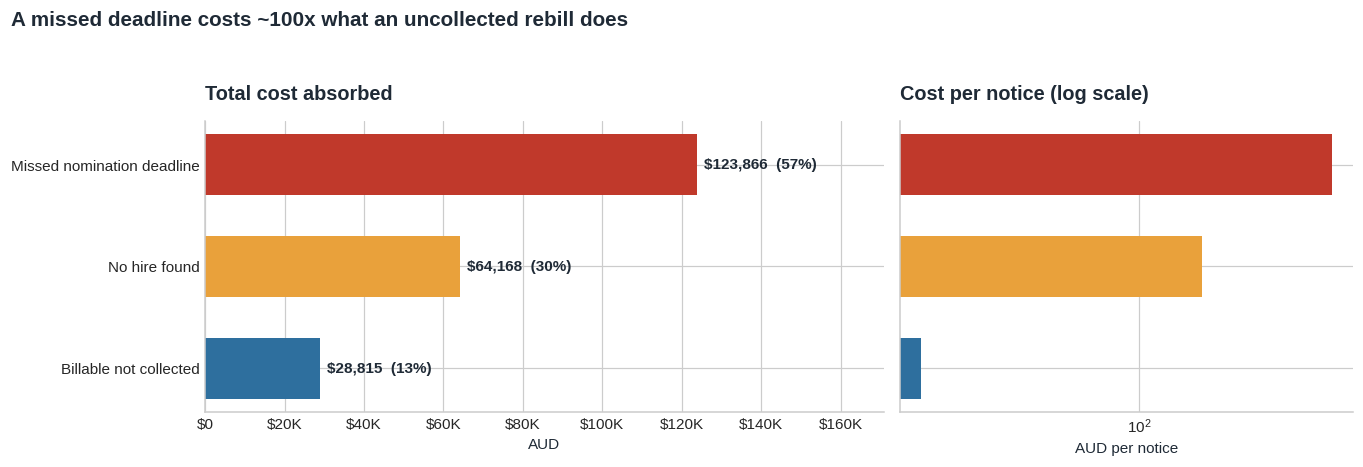

In [14]:
g = (df[df.company_cost_aud > 0].groupby("cost_cause")
     .agg(notices=("company_cost_aud", "size"), cost=("company_cost_aud", "sum"))
     .sort_values("cost"))
g["share"] = g.cost / g.cost.sum()
g["avg_per_notice"] = g.cost / g.notices

for c, r in g.sort_values("cost", ascending=False).iterrows():
    print(f"  {c:<28} {money(r.cost):>10}  {r.share:>6.1%}   "
          f"{int(r.notices):>5,} notices   avg {money(r.avg_per_notice):>7}")
g.sort_values("cost", ascending=False).to_csv(REPORTS / "cost_by_root_cause.csv")

colours = {"Missed nomination deadline": RED, "No hire found": AMBER,
           "Billable not collected": BLUE}

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.0),
                             gridspec_kw={"width_ratios": [1.5, 1]})
bars = a1.barh(g.index, g.cost, color=[colours.get(c, GREY) for c in g.index], height=0.6)
for b, (_, r) in zip(bars, g.iterrows()):
    a1.text(b.get_width() + g.cost.max() * 0.015, b.get_y() + b.get_height()/2,
            f"{money(r.cost)}  ({r.share:.0%})", va="center", fontsize=10,
            color=INK, fontweight="bold")
a1.xaxis.set_major_formatter(mticker.FuncFormatter(aud))
a1.set_xlim(0, g.cost.max() * 1.38)
style(a1, "Total cost absorbed", "AUD")

a2.barh(g.index, g.avg_per_notice, color=[colours.get(c, GREY) for c in g.index], height=0.6)
a2.set_yticklabels([])
a2.xaxis.set_major_formatter(mticker.FuncFormatter(aud))
a2.set_xscale("log")
style(a2, "Cost per notice (log scale)", "AUD per notice")

fig.suptitle("A missed deadline costs ~100x what an uncollected rebill does",
             fontsize=13.5, fontweight="bold", color=INK, x=0.012, ha="left", y=1.05)
plt.tight_layout()
plt.savefig(CHARTS / "01_cost_by_root_cause.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.3 The 21-day cliff

The single most important chart in the project, and the clearest picture of how
liability transfer works. Fines only — tolls have no deadline to miss.

Left of the line, the penalty leaves the company's books and costs nothing. Right of
the line, the company owns it outright. There is no gradient between the two.

  Fines requiring nomination       3,269
  Median processing time               8 days
  90th percentile                     22 days
  Missed the deadline                338  (10.3%)

  Penalty value nominated on time    $990,213   -> cost to company $56,129
  Penalty value nominated late       $129,269   -> cost to company $129,269


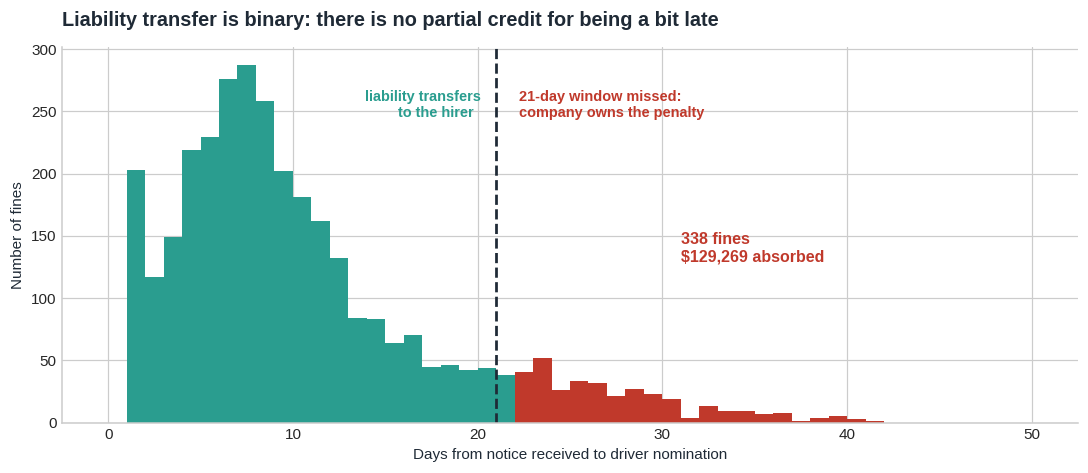

In [15]:
fines = df[df.requires_nomination == 1]
on_time = fines[fines.processing_days <= NOMINATION_WINDOW_DAYS]
late = fines[fines.processing_days > NOMINATION_WINDOW_DAYS]

print(f"  Fines requiring nomination     {len(fines):>7,}")
print(f"  Median processing time          {fines.processing_days.median():>6.0f} days")
print(f"  90th percentile                 {fines.processing_days.quantile(0.9):>6.0f} days")
print(f"  Missed the deadline            {len(late):>7,}  ({len(late)/len(fines):.1%})")
print()
print(f"  Penalty value nominated on time {money(on_time.penalty_amount.sum()):>11}"
      f"   -> cost to company {money(on_time.company_penalty_cost.sum())}")
print(f"  Penalty value nominated late    {money(late.penalty_amount.sum()):>11}"
      f"   -> cost to company {money(late.company_penalty_cost.sum())}")

fig, ax = plt.subplots(figsize=(10, 4.4))
bins = np.arange(0, 51, 1)
counts, edges = np.histogram(fines.processing_days, bins=bins)
ax.bar(edges[:-1], counts, width=1.0, align="edge",
       color=[RED if e > NOMINATION_WINDOW_DAYS else TEAL for e in edges[:-1]])
ax.axvline(NOMINATION_WINDOW_DAYS, color=INK, ls="--", lw=1.8)
ax.text(NOMINATION_WINDOW_DAYS - 0.8, counts.max()*0.93,
        "liability transfers\nto the hirer  ", fontsize=9.5, color=TEAL,
        fontweight="bold", va="top", ha="right")
ax.text(NOMINATION_WINDOW_DAYS + 0.8, counts.max()*0.93,
        "  21-day window missed:\n  company owns the penalty", fontsize=9.5,
        color=RED, fontweight="bold", va="top")
ax.text(31, counts.max()*0.45, f"{len(late):,} fines\n{money(late.company_penalty_cost.sum())} absorbed",
        fontsize=10.5, color=RED, fontweight="bold")
style(ax, "Liability transfer is binary: there is no partial credit for being a bit late",
      "Days from notice received to driver nomination", "Number of fines")
plt.tight_layout()
plt.savefig(CHARTS / "02_nomination_deadline_cliff.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.4 Cost over time

The question: do bad months happen because **more notices arrive**, or because the
**team falls behind**? Grey bars are cost; the dark line is the share of fines missing
the deadline. If they move together while volume stays flat, it is a staffing problem
wearing a compliance problem's clothes.

Worst months by cost absorbed:
  2025-08     $28,114   missed deadline 44.6%   avg processing 20.4 days   314 notices
  2025-07     $24,247   missed deadline 38.6%   avg processing 19.7 days   311 notices
  2025-01     $22,583   missed deadline 39.3%   avg processing 17.8 days   365 notices
  2024-12     $21,772   missed deadline 34.0%   avg processing 15.3 days   343 notices

Correlation between notice volume and cost:      +0.07
Correlation between missed-deadline rate and cost: +0.87


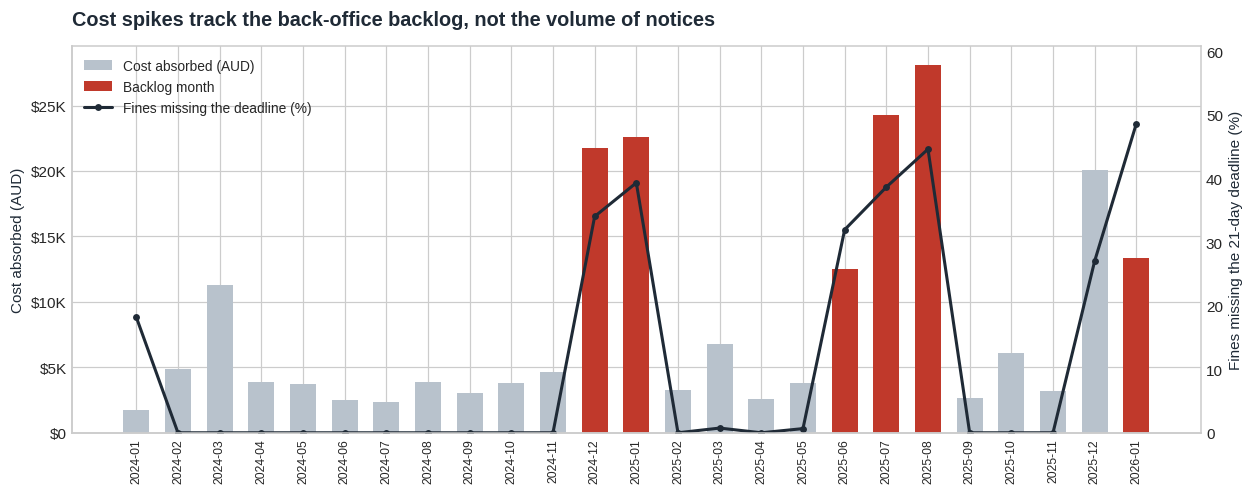

In [16]:
m = (df.groupby("notice_month")
     .agg(cost=("company_cost_aud", "sum"), notices=("company_cost_aud", "size"),
          late_rate=("missed_deadline", "mean"),
          avg_processing=("processing_days", "mean")).reset_index())
m.to_csv(REPORTS / "monthly_cost.csv", index=False)

print("Worst months by cost absorbed:")
for _, r in m.nlargest(4, "cost").iterrows():
    print(f"  {r.notice_month}   {money(r.cost):>9}   missed deadline {r.late_rate:>5.1%}"
          f"   avg processing {r.avg_processing:>4.1f} days   {int(r.notices):,} notices")
print(f"\nCorrelation between notice volume and cost:      {m.notices.corr(m.cost):+.2f}")
print(f"Correlation between missed-deadline rate and cost: {m.late_rate.corr(m.cost):+.2f}")

fig, ax1 = plt.subplots(figsize=(11.5, 4.6))
x = np.arange(len(m))
ax1.bar(x, m.cost, color=GREY, width=0.62, label="Cost absorbed (AUD)")
hot = (m.late_rate > m.late_rate.mean() + m.late_rate.std()).to_numpy()
ax1.bar(x[hot], m.loc[hot, "cost"], color=RED, width=0.62, label="Backlog month")
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(aud))
ax1.set_xticks(x); ax1.set_xticklabels(m.notice_month, rotation=90, fontsize=8)
style(ax1, "Cost spikes track the back-office backlog, not the volume of notices",
      None, "Cost absorbed (AUD)")

ax2 = ax1.twinx()
ax2.plot(x, m.late_rate * 100, color=INK, lw=2, marker="o", ms=3.5,
         label="Fines missing the deadline (%)")
ax2.set_ylabel("Fines missing the 21-day deadline (%)", fontsize=10, color=INK)
ax2.grid(False); ax2.set_ylim(0, max(m.late_rate.max()*100*1.25, 5))

h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1+h2, l1+l2, loc="upper left", fontsize=9)
plt.tight_layout()
plt.savefig(CHARTS / "03_monthly_cost_vs_backlog.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.5 Volume is not cost

Tolls dominate the queue and contribute very little cost, because a toll is worth a
few dollars and rebills automatically against a card. Camera-detected fines are a
fraction of the volume and nearly all of the risk, because each one is a few hundred
dollars that becomes permanent if a deadline slips.

Any process that works the notice queue first-in-first-out spends most of its effort
on the cheapest items. This is the argument for triage, before any model exists.

  Type             Notices   Vol %       Cost  Cost %  $/notice
  Speed Camera       1,121   14.5%    $80,402   37.1%       $72
  Bus Lane             489    6.3%    $37,407   17.3%       $76
  Parking              975   12.6%    $33,924   15.6%       $35
  Red Light            382    4.9%    $30,637   14.1%       $80
  Mobile Phone         302    3.9%    $21,263    9.8%       $70
  Toll               4,465   57.7%    $13,217    6.1%        $3


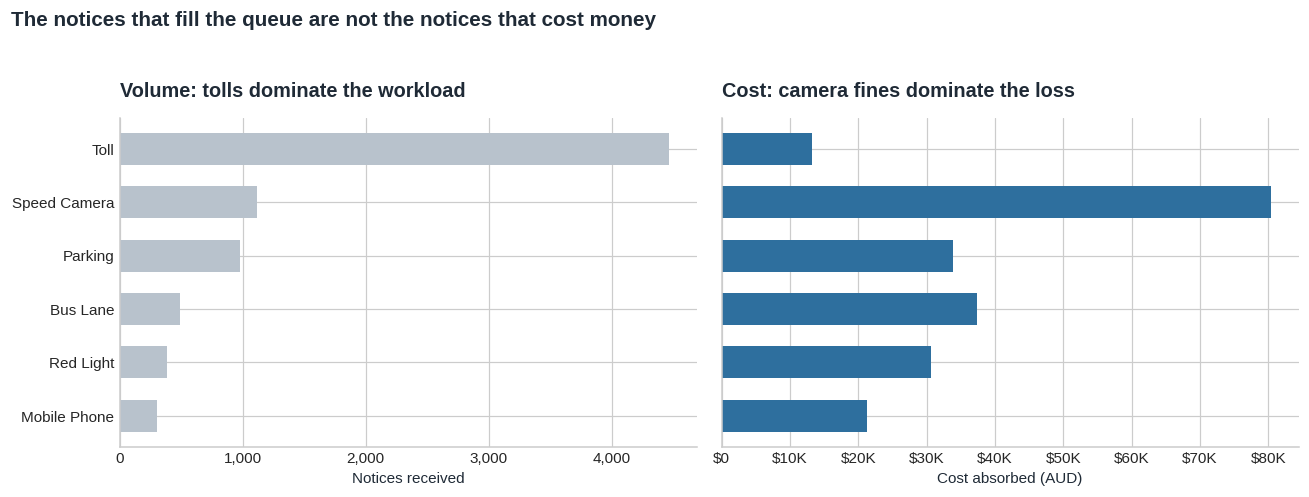

In [17]:
g = (df.groupby("infringement_type")
     .agg(notices=("company_cost_aud", "size"), face_value=("penalty_amount", "sum"),
          cost=("company_cost_aud", "sum")).sort_values("cost", ascending=False))
g["vol_share"] = g.notices / g.notices.sum()
g["cost_share"] = g.cost / g.cost.sum()
g["cost_per_notice"] = g.cost / g.notices
g.to_csv(REPORTS / "cost_by_infringement_type.csv")

print(f"  {'Type':<15}{'Notices':>9}{'Vol %':>8}{'Cost':>11}{'Cost %':>8}{'$/notice':>10}")
for t, r in g.iterrows():
    print(f"  {t:<15}{int(r.notices):>9,}{r.vol_share:>8.1%}"
          f"{money(r.cost):>11}{r.cost_share:>8.1%}{money(r.cost_per_notice):>10}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.3))
order = g.sort_values("notices").index
a1.barh(order, g.loc[order, "notices"], color=GREY, height=0.6)
a1.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
style(a1, "Volume: tolls dominate the workload", "Notices received")
a2.barh(order, g.loc[order, "cost"], color=BLUE, height=0.6)
a2.set_yticklabels([])
a2.xaxis.set_major_formatter(mticker.FuncFormatter(aud))
style(a2, "Cost: camera fines dominate the loss", "Cost absorbed (AUD)")
fig.suptitle("The notices that fill the queue are not the notices that cost money",
             fontsize=13.5, fontweight="bold", color=INK, x=0.012, ha="left", y=1.04)
plt.tight_layout()
plt.savefig(CHARTS / "04_volume_vs_cost_by_type.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.6 Who never pays a billable

Scoped carefully: this covers **only** notices where a billable amount was raised —
toll rebills and processing fees. Transferred penalties are excluded, because they are
not the company's money to collect.

Collection failure concentrates in hirers whose payment details were never captured at
pickup. That makes it a **front-counter** problem, not a back-office one.

Notices with a billable raised: 6,997
Overall collection failure rate: 18.9%

Share of billables never collected (%):
resid            Domestic  Overseas
card                               
Card on file         11.9      24.3
No card on file      29.9      43.5

Value lost (AUD):
resid            Domestic  Overseas
card                               
Card on file      10826.0    2708.0
No card on file   10089.0    5193.0


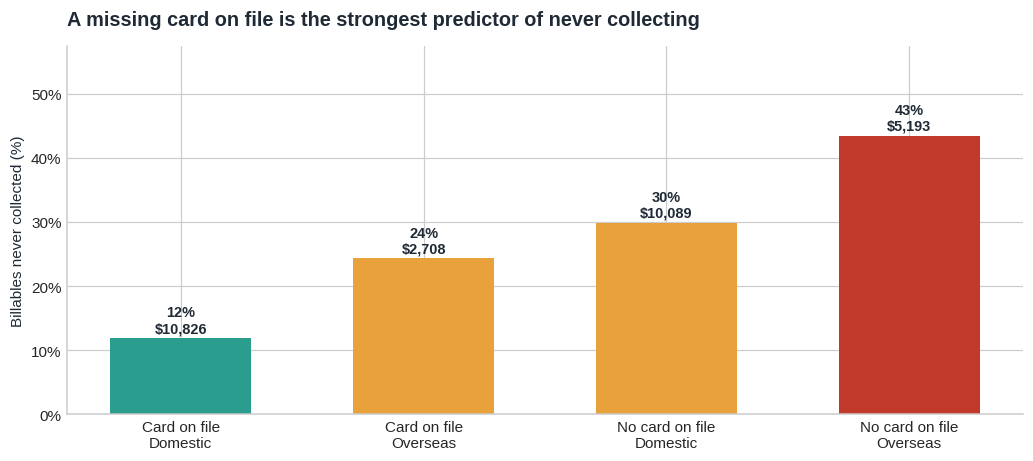

In [18]:
b = df[df.billable_amount > 0].copy()
b["card"] = np.where(b.card_on_file == 1, "Card on file", "No card on file")
b["resid"] = np.where(b.country_of_residence == "Australia", "Domestic", "Overseas")

print(f"Notices with a billable raised: {len(b):,}")
print(f"Overall collection failure rate: {b.billing_failed.mean():.1%}\n")
print("Share of billables never collected (%):")
print((b.pivot_table(index="card", columns="resid", values="billing_failed",
                     aggfunc="mean") * 100).round(1).to_string())
print("\nValue lost (AUD):")
print(b.pivot_table(index="card", columns="resid", values="billable_lost_aud",
                    aggfunc="sum").round(0).to_string())
b.pivot_table(index="card", columns="resid", values="billing_failed",
              aggfunc="mean").to_csv(REPORTS / "billing_failure_by_segment.csv")

seg = (b.groupby(["card", "resid"])
       .agg(fail=("billing_failed", "mean"), lost=("billable_lost_aud", "sum"),
            n=("billable_lost_aud", "size")).reset_index())
seg["label"] = seg.card + "\n" + seg.resid
seg = seg.sort_values("fail")

fig, ax = plt.subplots(figsize=(9.5, 4.3))
cols = [RED if f > 0.30 else (AMBER if f > 0.15 else TEAL) for f in seg.fail]
bars = ax.bar(seg.label, seg.fail * 100, color=cols, width=0.58)
for bar, (_, r) in zip(bars, seg.iterrows()):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.9,
            f"{r.fail:.0%}\n{money(r.lost)}", ha="center", fontsize=9.5,
            color=INK, fontweight="bold")
ax.set_ylim(0, seg.fail.max()*100*1.32)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
style(ax, "A missing card on file is the strongest predictor of never collecting",
      None, "Billables never collected (%)")
plt.tight_layout()
plt.savefig(CHARTS / "05_billing_failure_by_segment.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.7 Sizing the opportunity

An analysis that stops at "we lose $X" gets nodded at and forgotten. One that says
"here is what is recoverable, under these stated assumptions" gets acted on.

The success rates below are **assumptions, not findings**. They are written as explicit
numbers in the code so a manager can argue with them, which is the point.

In [19]:
deadline_cost = df.loc[df.cost_cause == "Missed nomination deadline", "company_cost_aud"].sum()
nohire_cost = df.loc[df.cost_cause == "No hire found", "company_cost_aud"].sum()
nocard_cost = df.loc[(df.cost_cause == "Billable not collected")
                     & (df.card_on_file == 0), "company_cost_aud"].sum()
months = df.notice_month.nunique()

scenarios = [
    ("Clear the nomination backlog (80% of misses avoided)", deadline_cost * 0.80),
    ("Reconcile fleet movements daily (60% of no-hire resolved)", nohire_cost * 0.60),
    ("Mandate a card on file at pickup (50% of that segment)", nocard_cost * 0.50),
]
total = sum(v for _, v in scenarios)

for name, v in scenarios:
    print(f"  {name:<58} {money(v):>10}")
print(f"  {'-'*58} {'-'*10}")
print(f"  {f'TOTAL recoverable over {months} months':<58} {money(total):>10}")
print(f"  {'Equivalent per 12 months':<58} {money(total/months*12):>10}")
print(f"\n  Note: {(scenarios[0][1]+scenarios[1][1])/total:.0%} of the recoverable amount comes from"
      f" process fixes,\n  not from chasing customers harder.")

pd.DataFrame([{"intervention": n, "recoverable_aud": round(v, 2)} for n, v in scenarios]
             + [{"intervention": "TOTAL", "recoverable_aud": round(total, 2)},
                {"intervention": "ANNUALISED", "recoverable_aud": round(total/months*12, 2)}]
             ).to_csv(REPORTS / "opportunity_sizing.csv", index=False)

  Clear the nomination backlog (80% of misses avoided)          $99,093
  Reconcile fleet movements daily (60% of no-hire resolved)     $38,501
  Mandate a card on file at pickup (50% of that segment)         $7,641
  ---------------------------------------------------------- ----------
  TOTAL recoverable over 25 months                             $145,235
  Equivalent per 12 months                                      $69,713

  Note: 95% of the recoverable amount comes from process fixes,
  not from chasing customers harder.


---
# Part 4 — Two risks, two models, one work queue

**The question:** on the day a notice arrives, which ones should the team work first?

Part 3 showed cost arrives through two structurally different failures, driven by
different things and owned by different teams. So this is not one prediction problem,
it is two:

| | Predicts | Scope | Owner | Driven by |
|---|---|---|---|---|
| **Model 1 — Deadline risk** | Will this fine miss the 21-day window? | Fines matched to a hire | Back office | Team capacity, seasonality |
| **Model 2 — Collection risk** | Will this billable ever be collected? | Notices with a billable raised | Billing / front counter | Hirer payment and contact details |

Both use day-one information only. An earlier version of this project trained a single
model on everything and scored barely better than guessing, because it was trying to
predict two unrelated things with one set of features.

**Spoiler, stated up front rather than buried:** only one of these turns out to be
worth deploying. Model 1 barely separates individual notices, and section 4.3 explains
why that is the correct answer rather than a modelling failure. Section 4.7 then
benchmarks the whole thing against a deliberately stupid rule, which does better than
expected. Both results are in here on purpose.

The two are then combined into a single **expected cost** per notice, which is what
actually orders the work queue:

```
expected cost = P(miss deadline) x penalty                       <- Model 1
              + (1 - P(miss deadline)) x P(no collect) x billable <- Model 2
```

For a toll, `P(miss deadline)` is zero by definition — there is no deadline — so the
formula reduces to collection risk alone. For a fine, the penalty term dominates,
because a penalty is worth roughly a hundred times the processing fee. The formula
encodes the domain rules rather than assuming one model can learn them.

### 4.1 Features, and the columns that must never be features

**Target leakage** is the easiest way to build a model that scores brilliantly and
fails in production. Several columns here are only known *after* the outcome:
`processing_days`, `missed_deadline`, `status`, `billed_recovered`, `billing_date`,
`company_cost_aud`. On the day a notice arrives, none of them exist.

They are listed explicitly and the exclusion is **asserted in code**, not merely
intended. If someone asks how I know the model is not cheating, that assertion is the
answer.

Note the feature sets differ by design. The back office does not know or care who the
hirer is when it nominates a driver — its constraint is workload. The billing team
cares about nothing else.

**One encoding detail worth flagging, because it cost me a working model.** Month goes
in as a *category*, not as the number 1–12. My first version used the raw integer and
Model 1 scored AUC 0.485 — worse than a coin toss. The reason is that month is
cyclical: December and January are adjacent in reality but sit at opposite ends of a
numeric scale, so a linear model can only fit a monotonic slope through them. It
cannot express "high in December *and* high in January", so it spread the risk across
the middle of the year instead and predicted 24% risk in months where the true rate
was 0.2%. One-hot encoding gives each month its own coefficient and the problem
disappears. Nothing errored — the model just quietly didn't work.

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             brier_score_loss, classification_report, confusion_matrix)

CUTOFF = "2025-01-01"

# Known only AFTER the outcome. Never features.
POST_OUTCOME_COLUMNS = [
    "processing_days", "missed_deadline", "back_office_action_date",
    "nomination_due_date", "status", "company_penalty_cost", "billable_amount",
    "billed_recovered", "billing_date", "billable_lost_aud", "company_cost_aud",
    "liability_transferred", "billing_failed", "cost_cause",
]

# Model 1 -- deadline risk. Process and calendar features only.
#
# notice_month is CATEGORICAL, not numeric, and that is deliberate. Month is a
# cyclical variable: December and January are adjacent in reality but sit at
# opposite ends of a 1-12 numeric scale. Fed as a number, a linear model can
# only fit a monotonic slope through it, so it cannot say "high in December AND
# high in January" -- it smears the risk across the middle of the year instead.
# One-hot encoding lets each month carry its own coefficient.
M1_NUM = ["penalty_amount", "days_offence_to_notice", "notices_prior_14d",
          "notice_dayofweek"]
M1_CAT = ["notice_month_name", "infringement_type", "issuing_authority",
          "pickup_branch", "home_branch"]

# Model 2 -- collection risk. Hirer and amount features.
M2_NUM = ["penalty_amount", "days_since_hire_end", "hire_days", "days_offence_to_notice"]
M2_CAT = ["infringement_type", "is_toll", "hirer_type", "is_overseas", "licence_state",
          "email_on_file", "phone_on_file", "card_on_file", "pickup_branch"]

work = df.copy()
work["notice_month_name"] = work.notice_received_date.dt.strftime("%b")
work["notice_dayofweek"] = work.notice_received_date.dt.dayofweek
work["is_overseas"] = np.where(work.country_of_residence == "Australia", "Domestic", "Overseas")
work["is_toll"] = np.where(work.requires_nomination == 1, "Fine", "Toll")
for c in ["email_on_file", "phone_on_file", "card_on_file"]:
    work[c] = work[c].astype("Int64").astype(str)

leaked = set(M1_NUM + M1_CAT + M2_NUM + M2_CAT) & set(POST_OUTCOME_COLUMNS)
assert not leaked, f"TARGET LEAKAGE: {leaked} must not be features"

m1 = work[(work.is_matched == 1) & (work.requires_nomination == 1)].copy()
m2 = work[work.billable_amount > 0].copy()

print(f"Model 1 scope (fines, matched)      {len(m1):>7,}   "
      f"missed deadline {m1.missed_deadline.mean():.1%}")
print(f"Model 2 scope (billable raised)     {len(m2):>7,}   "
      f"collection failed {m2.billing_failed.mean():.1%}")
print(f"\nPost-outcome columns blocked        {len(POST_OUTCOME_COLUMNS):>7}")
print("Leakage assertion passed: no post-outcome column is in either feature set.")

Model 1 scope (fines, matched)        3,088   missed deadline 10.4%
Model 2 scope (billable raised)       6,997   collection failed 18.9%

Post-outcome columns blocked             14
Leakage assertion passed: no post-outcome column is in either feature set.


### 4.2 The pipeline, and why the split is by time

**Preprocessing lives inside a `Pipeline`.** Imputers and the scaler are fitted on the
training fold only, so no information about the test period leaks in through a mean or
a median. Doing it by hand before splitting is a very common and very invisible bug.

**The split is by date, not at random.** Train on notices received in 2024, test on
2025 onward. A random split lets the model learn from the future, which a real
deployment cannot do — and it flatters the score.

In [21]:
def build_pipeline(model, num, cat):
    numeric = Pipeline([("impute", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler())])
    categorical = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                            ("encode", OneHotEncoder(handle_unknown="ignore",
                                                     sparse_output=False))])
    pre = ColumnTransformer([("num", numeric, num), ("cat", categorical, cat)])
    return Pipeline([("prep", pre), ("model", model)])


def time_split(sub, target, num, cat):
    tr = sub.notice_received_date < CUTOFF
    X, y = sub[num + cat], sub[target].astype(int)
    return X[tr], X[~tr], y[tr], y[~tr], sub[~tr]


def evaluate(name, pipe, X_te, y_te):
    p = pipe.predict_proba(X_te)[:, 1]
    res = {"model": name, "n_test": len(y_te), "base_rate": y_te.mean(),
           "roc_auc": roc_auc_score(y_te, p),
           "pr_auc": average_precision_score(y_te, p),
           "brier": brier_score_loss(y_te, p)}
    print(f"  {name:<34} AUC {res['roc_auc']:.3f}   PR {res['pr_auc']:.3f}   "
          f"Brier {res['brier']:.3f}   (base rate {y_te.mean():.1%})")
    return res, p


print("Pipeline and split helpers defined.")

Pipeline and split helpers defined.


### 4.3 Model 1 — deadline risk

Trained on 2024, tested on 2025. Pay attention to what this model can and cannot see,
because it is the most honest result in the project.

It can learn the **recurring** December–January backlog, because that pattern appears
in the 2024 training data. It cannot possibly learn the **June–August 2025** backlog,
because that was caused by a staff member leaving in 2025 — an event with no
representation in the training period at all.

That limitation is not a flaw to hide. It is the finding: no model predicts a staffing
decision. A model can flag the seasonal risk you already know is coming; only the
capacity fix from Part 3 addresses the rest.

**Read the per-period AUCs carefully — they are near 0.5, and that is correct.** Within
a backlog month, whether any individual notice slips past day 21 comes down to where it
landed in a queue the team was already behind on. There is nothing printed on the
notice that determines it. So the model can identify *which periods* are dangerous, but
not *which notice* within a dangerous period, and no amount of tuning would change
that, because the information does not exist in the data.

That makes Model 1 a **diagnostic, not a deployable ranker**. Its value is the negative
result: it demonstrates that deadline risk is structural rather than notice-level, which
is precisely why the answer is the capacity fix in Part 3 and not a smarter score.

In [22]:
X_tr1, X_te1, y_tr1, y_te1, te1 = time_split(m1, "missed_deadline", M1_NUM, M1_CAT)
print(f"  Train (2024)   {len(y_tr1):>6,}   missed deadline {y_tr1.mean():.1%}")
print(f"  Test  (2025+)  {len(y_te1):>6,}   missed deadline {y_te1.mean():.1%}\n")

pipe1 = build_pipeline(
    LogisticRegression(max_iter=2000, class_weight="balanced"), M1_NUM, M1_CAT)
pipe1.fit(X_tr1, y_tr1)
res1, p1 = evaluate("Model 1 - deadline risk", pipe1, X_te1, y_te1)

# Where does it do well, and where does it fail? Split the test period by the
# cause of the backlog.
te1 = te1.copy(); te1["pred"] = p1
te1["period"] = np.where(te1.notice_received_date.dt.month.isin([1, 12]),
                         "Dec-Jan (seasonal, seen in training)",
                         np.where(te1.notice_received_date.dt.month.isin([6, 7, 8]),
                                  "Jun-Aug 2025 (new staffing gap)", "Rest of year"))
print("\nHow well it separates, by period:")
for per, grp in te1.groupby("period"):
    if grp.missed_deadline.nunique() < 2:
        print(f"  {per:<38} n={len(grp):>5,}  (no variation to score)")
        continue
    print(f"  {per:<38} n={len(grp):>5,}  actual miss rate {grp.missed_deadline.mean():>5.1%}"
          f"   mean predicted {grp.pred.mean():>5.1%}   AUC {roc_auc_score(grp.missed_deadline, grp.pred):.3f}")

  Train (2024)    1,482   missed deadline 3.5%
  Test  (2025+)   1,606   missed deadline 16.8%

  Model 1 - deadline risk            AUC 0.553   PR 0.207   Brier 0.195   (base rate 16.8%)

How well it separates, by period:
  Dec-Jan (seasonal, seen in training)   n=  337  actual miss rate 37.1%   mean predicted 39.9%   AUC 0.414
  Jun-Aug 2025 (new staffing gap)        n=  373  actual miss rate 38.3%   mean predicted  1.0%   AUC 0.547
  Rest of year                           n=  896  actual miss rate  0.2%   mean predicted  1.1%   AUC 0.605


### 4.4 Model 2 — collection risk, and choosing the algorithm

Two candidates:

**Logistic Regression** — the answer we want is yes or no (collected or not), and
logistic regression outputs a probability between 0 and 1, which is exactly what a
triage score needs. `class_weight="balanced"` matters: only about a fifth of billables
fail, so without it the model learns to predict "will collect" for everything, looks
80% accurate, and is useless.

*Linear regression would be the wrong tool and is not used.* It predicts a quantity and
can happily output -0.3 or 1.8 for a yes/no question.

**HistGradientBoostingClassifier** — hundreds of shallow decision trees trained in
sequence, each focusing on the errors of the ones before it. The modern default for
tabular data, and usually the winner.

Watch which one wins here, and check the feature importance in 4.6 for why.

  Train (2024)    3,480   collection failed 18.5%
  Test  (2025+)   3,517   collection failed 19.3%

  Model 2 / Logistic Regression      AUC 0.681   PR 0.342   Brier 0.216   (base rate 19.3%)


  Model 2 / Gradient Boosting        AUC 0.647   PR 0.297   Brier 0.154   (base rate 19.3%)

  Selected for Model 2: Logistic Regression


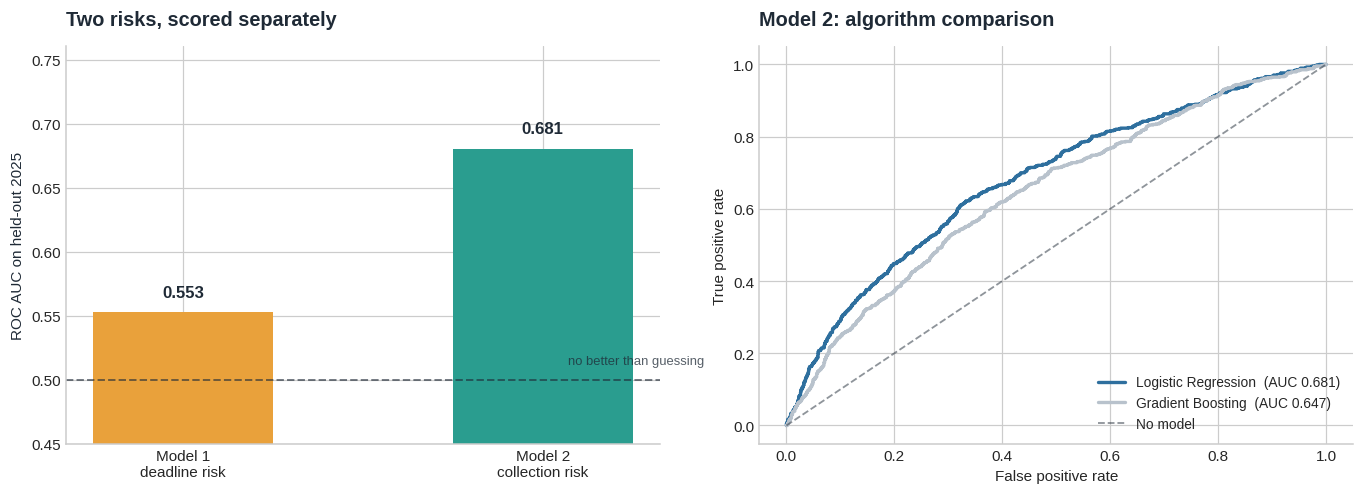

In [23]:
X_tr2, X_te2, y_tr2, y_te2, te2 = time_split(m2, "billing_failed", M2_NUM, M2_CAT)
print(f"  Train (2024)   {len(y_tr2):>6,}   collection failed {y_tr2.mean():.1%}")
print(f"  Test  (2025+)  {len(y_te2):>6,}   collection failed {y_te2.mean():.1%}\n")

candidates = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=250, learning_rate=0.06, max_leaf_nodes=20,
        min_samples_leaf=30, l2_regularization=1.0, random_state=42),
}

preds2, fitted2, perf = {}, {}, [res1]
for name, mdl in candidates.items():
    pipe = build_pipeline(mdl, M2_NUM, M2_CAT)
    pipe.fit(X_tr2, y_tr2)
    res, p = evaluate(f"Model 2 / {name}", pipe, X_te2, y_te2)
    preds2[name], fitted2[name] = p, pipe
    perf.append(res)

pd.DataFrame(perf).round(4).to_csv(REPORTS / "model_performance.csv", index=False)
best_name = max(perf[1:], key=lambda r: r["roc_auc"])["model"].split(" / ")[1]
pipe2 = fitted2[best_name]
print(f"\n  Selected for Model 2: {best_name}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.6))

names = ["Model 1\ndeadline risk", "Model 2\ncollection risk"]
vals = [res1["roc_auc"], max(r["roc_auc"] for r in perf[1:])]
bars = a1.bar(names, vals, color=[AMBER, TEAL], width=0.5)
for b, v in zip(bars, vals):
    a1.text(b.get_x()+b.get_width()/2, v+0.012, f"{v:.3f}", ha="center",
            fontsize=11, fontweight="bold", color=INK)
a1.axhline(0.5, color=INK, ls="--", lw=1.3, alpha=0.6)
a1.text(1.45, 0.512, "no better than guessing", fontsize=8.5, color=INK,
        alpha=0.75, ha="right")
a1.set_ylim(0.45, max(vals)+0.08)
style(a1, "Two risks, scored separately", None, "ROC AUC on held-out 2025")

for (name, p), colour in zip(preds2.items(), [BLUE, GREY]):
    fpr, tpr, _ = roc_curve(y_te2, p)
    a2.plot(fpr, tpr, lw=2.2, color=colour,
            label=f"{name}  (AUC {roc_auc_score(y_te2, p):.3f})")
a2.plot([0, 1], [0, 1], ls="--", lw=1.2, color=INK, alpha=0.5, label="No model")
a2.set_xlabel("False positive rate", fontsize=10)
a2.set_ylabel("True positive rate", fontsize=10)
a2.legend(loc="lower right", fontsize=9)
style(a2, "Model 2: algorithm comparison")
plt.tight_layout()
plt.savefig(CHARTS / "06_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.5 The threshold is a business decision

A 0.50 threshold is a default, not an answer. Here a **false positive** costs a few
minutes of unnecessary chasing; a **false negative** costs the whole billable. Those
are not symmetric, so the threshold should not be either.

In [24]:
yhat = (preds2[best_name] >= 0.50).astype(int)
print(classification_report(y_te2, yhat, target_names=["Collected", "Not collected"],
                            digits=3))
cm = confusion_matrix(y_te2, yhat)
print(f"Confusion matrix    TN {cm[0,0]:>5}   FP {cm[0,1]:>5}")
print(f"                    FN {cm[1,0]:>5}   TP {cm[1,1]:>5}")
print(f"\nFalse alarms (FP):    {cm[0,1]:,} billables chased unnecessarily")
print(f"Missed failures (FN): {cm[1,0]:,} billables that quietly become company cost")

               precision    recall  f1-score   support

    Collected      0.867     0.715     0.784      2837
Not collected      0.314     0.544     0.398       680

     accuracy                          0.682      3517
    macro avg      0.591     0.629     0.591      3517
 weighted avg      0.760     0.682     0.709      3517

Confusion matrix    TN  2028   FP   809
                    FN   310   TP   370

False alarms (FP):    809 billables chased unnecessarily
Missed failures (FN): 310 billables that quietly become company cost


### 4.6 What drives each risk

Two panels, two different worlds — and that separation is the justification for
building two models rather than one.

The left panel is calendar and workload. The right panel is the hirer's payment
details. Almost no overlap, which is precisely why a single model with one combined
feature set performed poorly.

The right panel also answers "why did gradient boosting lose?" (if it did). Look at
the gap between the top feature and the rest: the signal is **one dominant flag plus a
few weak ones stacking up roughly additively** — the shape logistic regression handles
best. Boosted trees earn their advantage when features interact in complicated ways or
have sharp non-linear thresholds. There is little of that here, so the extra
flexibility mostly fit 2024's noise.

Model 1 - deadline risk:
  notices_prior_14d          +0.0492
  days_offence_to_notice     +0.0112
  pickup_branch              +0.0080
  notice_dayofweek           +0.0015
  notice_month_name          +0.0010

Model 2 - collection risk:
  card_on_file               +0.0891
  hirer_type                 +0.0165
  is_overseas                +0.0108
  email_on_file              +0.0101
  days_offence_to_notice     +0.0087
  days_since_hire_end        +0.0064


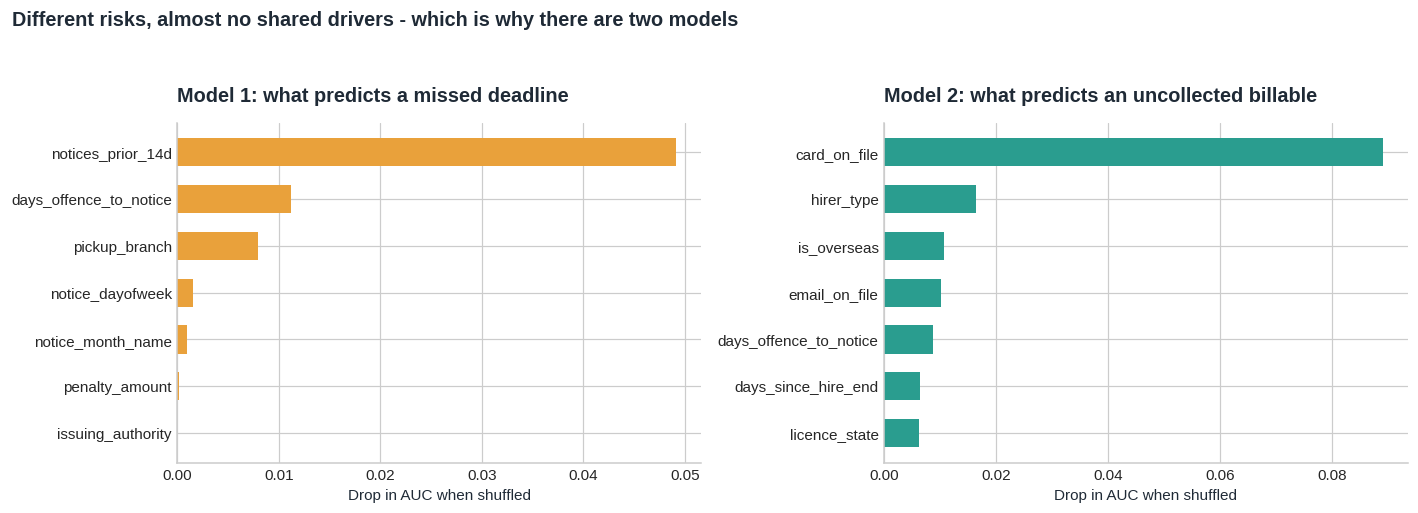

In [25]:
def importance(pipe, X_te, y_te):
    r = permutation_importance(pipe, X_te, y_te, n_repeats=8, random_state=42,
                               scoring="roc_auc", n_jobs=1)
    return (pd.DataFrame({"feature": X_te.columns, "importance": r.importances_mean})
            .sort_values("importance", ascending=False))


imp1 = importance(pipe1, X_te1, y_te1)
imp2 = importance(pipe2, X_te2, y_te2)
imp1.assign(model="M1 deadline risk").to_csv(REPORTS / "feature_importance_m1.csv", index=False)
imp2.assign(model="M2 collection risk").to_csv(REPORTS / "feature_importance_m2.csv", index=False)

print("Model 1 - deadline risk:")
for _, r in imp1.head(5).iterrows():
    print(f"  {r.feature:<26} {r.importance:+.4f}")
print("\nModel 2 - collection risk:")
for _, r in imp2.head(6).iterrows():
    print(f"  {r.feature:<26} {r.importance:+.4f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.4))
t1 = imp1.head(7).sort_values("importance")
a1.barh(t1.feature, t1.importance, color=AMBER, height=0.6)
style(a1, "Model 1: what predicts a missed deadline", "Drop in AUC when shuffled")
t2 = imp2.head(7).sort_values("importance")
a2.barh(t2.feature, t2.importance, color=TEAL, height=0.6)
style(a2, "Model 2: what predicts an uncollected billable", "Drop in AUC when shuffled")
fig.suptitle("Different risks, almost no shared drivers - which is why there are two models",
             fontsize=13, fontweight="bold", color=INK, x=0.012, ha="left", y=1.05)
plt.tight_layout()
plt.savefig(CHARTS / "07_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.7 The deliverable: one queue ordered by expected cost

Both models are now scored onto the same 2025 notices and combined through the domain
formula. This is the part a manager actually uses.

Three cases, handled explicitly rather than hoping a model infers them:

- **No hire found** — known the moment the lookup fails. The full penalty is certain
  cost, so these go straight to the top and route to fleet ops.
- **Fines** — expected cost is dominated by `P(miss deadline) x penalty`.
- **Tolls** — no deadline exists, so expected cost is `P(no collect) x (toll + fee)`.

In [26]:
q = work[work.notice_received_date >= CUTOFF].copy()

# --- Model 1: probability of missing the nomination deadline -----------------
q["p_miss_deadline"] = 0.0
fine_mask = (q.requires_nomination == 1) & (q.is_matched == 1)
q.loc[fine_mask, "p_miss_deadline"] = pipe1.predict_proba(
    q.loc[fine_mask, M1_NUM + M1_CAT])[:, 1]

# --- Model 2: probability a billable goes uncollected ------------------------
# Scored for every matched notice, since any of them could raise a billable.
q["p_no_collect"] = 0.0
matched_mask = q.is_matched == 1
q.loc[matched_mask, "p_no_collect"] = pipe2.predict_proba(
    q.loc[matched_mask, M2_NUM + M2_CAT])[:, 1]

# --- What is billable, and how much is at stake ------------------------------
q["billable_at_stake"] = np.where(q.requires_nomination == 1, FEE_INFRINGEMENT,
                                  q.penalty_amount + FEE_TOLL)

# --- Combine through the domain rules ----------------------------------------
q["expected_cost"] = np.where(
    q.is_matched == 0,
    q.penalty_amount,                                    # certain cost, no hirer
    q.p_miss_deadline * q.penalty_amount
    + (1 - q.p_miss_deadline) * q.p_no_collect * q.billable_at_stake)

q["route_to"] = np.where(q.is_matched == 0, "Fleet ops - no hire found",
                         np.where(q.requires_nomination == 1,
                                  "Back office - nominate now", "Billing - secure payment"))

q = q.sort_values("expected_cost", ascending=False).reset_index(drop=True)
total_q_cost = q.company_cost_aud.sum()

print(f"Scored {len(q):,} notices received from {CUTOFF} onward, "
      f"carrying {money(total_q_cost)} of actual cost.\n")
print(q.route_to.value_counts().to_string())

Scored 3,990 notices received from 2025-01-01 onward, carrying $149,283 of actual cost.

route_to
Billing - secure payment      2181
Back office - nominate now    1606
Fleet ops - no hire found      203


### 4.7b Does any of this beat a stupid rule?

This is the check that should come before claiming a model has value, and it is the
one most portfolio projects skip.

Part 3 established that a missed deadline costs roughly a hundred times an uncollected
rebill. So a manager with no model at all could just **sort the queue by penalty
amount, biggest first** — pure domain intuition, no data science, implementable in
Excel in about a minute.

If that rule performs as well as the models, the honest conclusion is that the models
are not earning their keep, and saying so is more useful than a flattering chart.

  Strategy                             top 10%   top 20%   top 30%
  Expected cost (both models)            50.5%     66.4%     78.8%
  Penalty amount only (no model)         43.1%     67.7%     86.2%
  Arrival order (no triage)              10.0%     20.0%     30.0%


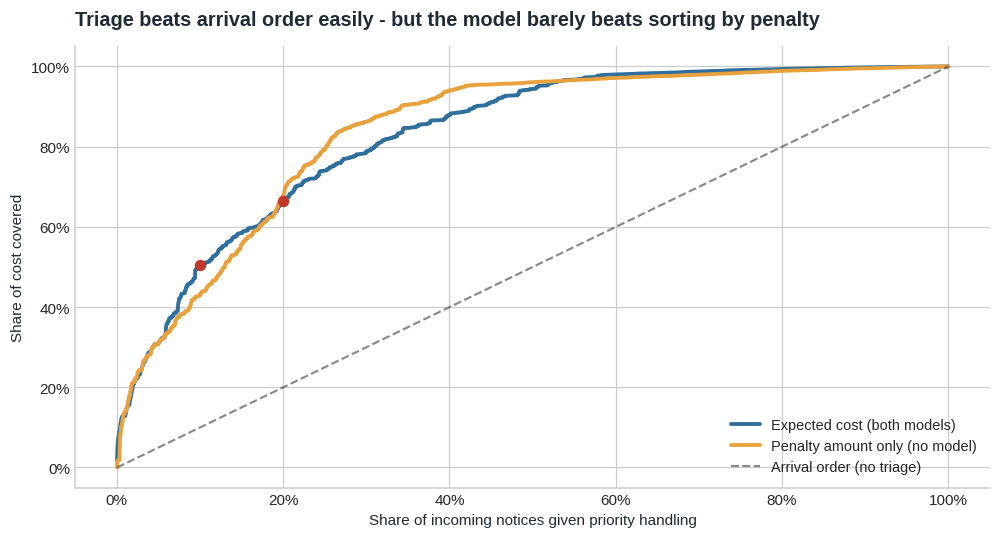

In [27]:
def capture_curve(series, ascending=False):
    """Cumulative share of actual cost captured when the queue is worked in the
    order given by `series`."""
    order = series.sort_values(ascending=ascending).index
    return (q.loc[order, "company_cost_aud"].cumsum() / total_q_cost).to_numpy()


strategies = {
    "Expected cost (both models)": capture_curve(q.expected_cost),
    "Penalty amount only (no model)": capture_curve(q.penalty_amount),
    "Arrival order (no triage)": np.linspace(0, 1, len(q)),
}

print(f"  {'Strategy':<34}{'top 10%':>10}{'top 20%':>10}{'top 30%':>10}")
rows = []
for name, cap in strategies.items():
    c10, c20, c30 = (cap[int(len(q)*m)-1] for m in (0.10, 0.20, 0.30))
    print(f"  {name:<34}{c10:>10.1%}{c20:>10.1%}{c30:>10.1%}")
    rows.append({"strategy": name, "top10pct": round(c10, 4),
                 "top20pct": round(c20, 4), "top30pct": round(c30, 4)})
pd.DataFrame(rows).to_csv(REPORTS / "triage_strategy_comparison.csv", index=False)

pct = np.arange(1, len(q)+1) / len(q) * 100
fig, ax = plt.subplots(figsize=(9.2, 5.0))
for (name, cap), colour, ls in zip(strategies.items(), [BLUE, AMBER, INK],
                                   ["-", "-", "--"]):
    ax.plot(pct, cap*100, lw=2.5 if ls == "-" else 1.4, color=colour, ls=ls,
            alpha=1.0 if ls == "-" else 0.55, label=name)
for mark in (0.10, 0.20):
    i = int(len(q)*mark) - 1
    ax.scatter([mark*100], [strategies["Expected cost (both models)"][i]*100],
               color=RED, zorder=5, s=42)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
style(ax, "Triage beats arrival order easily - but the model barely beats sorting by penalty",
      "Share of incoming notices given priority handling", "Share of cost covered")
ax.legend(loc="lower right", fontsize=9.5)
plt.tight_layout()
plt.savefig(CHARTS / "08_triage_value_curve.png", dpi=150, bbox_inches="tight")
plt.show()

**The result, stated plainly.** Both triage strategies crush working the queue in
arrival order — that part is a genuine and large win. But the model-based expected cost
only modestly beats sorting by penalty amount in the first 10% of the queue, and by the
20% mark the trivial rule is level with it or ahead.

So where does the modelling actually earn anything?

**It does not help with penalty risk, and Part 3 already told us why.** About 87% of
cost is absorbed penalties, and whether a penalty is absorbed depends on whether the
back office had capacity that week — not on anything printed on the notice. Sorting by
penalty amount captures nearly all the available value there, because the amount is the
only thing that varies usefully. The fix for that 87% is the capacity recommendation,
not a score.

**It does help with the collection pot, which the dumb rule cannot touch at all.** The
remaining cost sits in roughly 1,300 uncollected rebills and fees worth about $22 each.
Sorting by penalty amount buries a $9 toll at the bottom of the queue every single
time, so that pot is never worked. Model 2 separates those at AUC 0.68 using
`card_on_file` and residency — and it is the only way to prioritise thousands of small
items that are individually not worth a human decision.

That is the honest summary: **Model 2 is worth deploying on the small-ticket queue.
Model 1 is a diagnostic. And the headline cost problem is a staffing problem that no
model was ever going to solve.** I would rather hand a manager that than a chart
implying a score fixes everything.

In [28]:
for mark in (0.10, 0.20):
    i = int(len(q)*mark)
    top = q.head(i)
    print(f"Top {mark:.0%} by expected cost ({i:,} notices): "
          f"{money(top.company_cost_aud.sum())} of {money(total_q_cost)} "
          f"({top.company_cost_aud.sum()/total_q_cost:.0%})")

# The pot an amount-based rule structurally cannot reach: cost that arrived as an
# uncollected billable rather than as an absorbed penalty.
small = q[q.cost_cause == "Billable not collected"]
penalty_pot = q[q.company_penalty_cost > 0]

print(f"\nWhere the cost in this queue actually sits:")
print(f"  Absorbed penalties   {len(penalty_pot):>5,} notices   "
      f"{money(penalty_pot.company_cost_aud.sum()):>9}   "
      f"({penalty_pot.company_cost_aud.sum()/total_q_cost:.0%})")
print(f"  Uncollected billables{len(small):>5,} notices   "
      f"{money(small.company_cost_aud.sum()):>9}   "
      f"({small.company_cost_aud.sum()/total_q_cost:.0%})")

print(f"\nThe pot an amount-based rule cannot reach:")
print(f"  {len(small):,} uncollected billables, median value "
      f"{money(small.company_cost_aud.median())}")
print(f"  median penalty amount on those notices: {money(small.penalty_amount.median())}")
print(f"  -> sorted to the bottom of the queue by any amount-based rule,")
print(f"     but separable by Model 2 at AUC {max(r['roc_auc'] for r in perf[1:]):.3f}")

Top 10% by expected cost (399 notices): $75,398 of $149,283 (51%)
Top 20% by expected cost (798 notices): $99,126 of $149,283 (66%)

Where the cost in this queue actually sits:
  Absorbed penalties     473 notices    $134,831   (90%)
  Uncollected billables  680 notices     $14,451   (10%)

The pot an amount-based rule cannot reach:
  680 uncollected billables, median value $19
  median penalty amount on those notices: $17
  -> sorted to the bottom of the queue by any amount-based rule,
     but separable by Model 2 at AUC 0.681


### 4.8 Risk bands, routing, and an honest note on calibration

Banding turns a score into something an operator can use, and `route_to` sends each
notice to the team that can actually act on it. The test that matters: does **actual**
cost per notice rise across the bands? If it does, the ranking is trustworthy.

**One caveat stated plainly.** `class_weight="balanced"` deliberately inflates the
absolute probabilities to handle class imbalance, so `expected_cost` is a **priority
ranking, not a literal dollar forecast**. Comparing mean expected cost against mean
actual cost in the table below shows the gap. Wrapping the models in
`CalibratedClassifierCV` would fix it if the business ever needed the number itself —
for instance to provision a bad-debt reserve. Saying this out loud beats hoping nobody
checks.

In [29]:
q["priority"] = pd.qcut(q.expected_cost.rank(method="first", ascending=False),
                        q=[0, 0.05, 0.20, 0.50, 1.0],
                        labels=["P1 Critical", "P2 High", "P3 Medium", "P4 Low"])

keep = ["infringement_id", "registration", "notice_received_date", "infringement_type",
        "penalty_amount", "is_matched", "hirer_type", "country_of_residence",
        "card_on_file", "p_miss_deadline", "p_no_collect", "expected_cost",
        "priority", "route_to", "company_cost_aud"]
q[keep].to_csv(REPORTS / "triage_queue_scored.csv", index=False)

band = q.groupby("priority", observed=True).agg(
    notices=("expected_cost", "size"),
    mean_expected_cost=("expected_cost", "mean"),
    mean_actual_cost=("company_cost_aud", "mean"),
    total_actual_cost=("company_cost_aud", "sum"))
print(band.round(2).to_string())
print("\nActual cost per notice rises across the bands -> the ranking works.")
print("Expected vs actual differ in level -> it is a ranking, not a calibrated forecast.")

print("\nWhere the top 5% of the queue gets routed:")
print(q[q.priority == "P1 Critical"].route_to.value_counts().to_string())

print("\nTop of the work queue (what an operator would see each morning):")
q[["registration", "infringement_type", "penalty_amount", "p_miss_deadline",
   "p_no_collect", "expected_cost", "priority", "route_to"]].head(10)

             notices  mean_expected_cost  mean_actual_cost  total_actual_cost
priority                                                                     
P1 Critical      200              370.90            230.91           46182.55
P2 High          598               32.41             88.53           52943.52
P3 Medium       1197               15.10             34.91           41784.57
P4 Low          1995                6.01              4.20            8372.00

Actual cost per notice rises across the bands -> the ranking works.
Expected vs actual differ in level -> it is a ranking, not a calibrated forecast.

Where the top 5% of the queue gets routed:
route_to
Back office - nominate now    129
Fleet ops - no hire found      71

Top of the work queue (what an operator would see each morning):


,registration,infringement_type,penalty_amount,p_miss_deadline,p_no_collect,expected_cost,priority,route_to
0,UDK-15X,Speed Camera,2482.0,0.000000,0.000000,2482.000000,P1 Critical,Fleet ops - no hire found
1,JVA-85D,Speed Camera,2482.0,0.000000,0.000000,2482.000000,P1 Critical,Fleet ops - no hire found
2,SJC-71N,Speed Camera,2482.0,0.960410,0.643668,2384.578511,P1 Critical,Back office - nominate now
3,EDN-02L,Speed Camera,941.0,0.000000,0.000000,941.000000,P1 Critical,Fleet ops - no hire found
4,LGT-92T,Speed Camera,941.0,0.978162,0.358693,920.709400,P1 Critical,Back office - nominate now
5,MRH-95G,Speed Camera,941.0,0.976195,0.638820,919.101641,P1 Critical,Back office - nominate now
6,MBN-17R,Speed Camera,941.0,0.966960,0.315736,910.253393,P1 Critical,Back office - nominate now
7,UJR-62G,Speed Camera,941.0,0.962237,0.446975,906.021941,P1 Critical,Back office - nominate now
8,GVF-74F,Speed Camera,941.0,0.937127,0.368591,882.601543,P1 Critical,Back office - nominate now
9,XTJ-94H,Speed Camera,941.0,0.927983,0.267253,873.867387,P1 Critical,Back office - nominate now


---
# Findings

**1. The process mostly works, and the cost is in the tail.** The large majority of
penalty value is successfully transferred to hirers. Total absorbed cost is a recurring
four-figure monthly amount that nobody currently reports on.

**2. Cost is extremely concentrated.** Around a quarter of notices generate some cost,
but fewer than 10% of all notices — the absorbed penalties — account for roughly 87% of
it. The remaining thousand-odd failures are uncollected rebills worth about $22 each.
That concentration is the single strongest argument for triage over first-in-first-out
processing.

**3. Cost arrives through two unrelated failures with different owners.** Missed
nomination deadlines are a back-office capacity problem. Uncollected billables are a
front-counter data-capture problem. Reporting one combined number would hide both.

**4. Liability transfer is binary.** A fine nominated inside 21 days costs the company
nothing, regardless of whether the hirer is contactable, overseas, or cooperative —
the penalty is legally theirs. A fine nominated one day late costs the full amount,
permanently. There is no middle ground, which is what makes the deadline worth
protecting above everything else.

**5. Cost tracks the back-office backlog, not notice volume.** The worst months had
unremarkable volume and average processing times pressed against the 21-day deadline.

**6. Tolls are the opposite problem.** They cannot be transferred at all, so they carry
real collection risk — but each one is worth a few dollars. High volume, low stakes.

**7. A missing card on file is the strongest single predictor of an uncollected
billable**, and it is set at the counter, months before the notice ever arrives.

**8. Triage of any kind massively beats arrival order** — but the model only narrowly
beats sorting the queue by penalty amount, a rule requiring no data science at all. The
modelling earns its place on the small-ticket collection queue, where amount-based
sorting is useless, and not on the penalty risk that makes up most of the cost.

**9. The headline problem is a staffing problem.** Roughly 87% of absorbed cost comes
from penalties, and whether a penalty is absorbed depends on back-office capacity that
week rather than anything knowable about the notice. That is a resourcing decision, not
a modelling opportunity — and a model that implied otherwise would be actively
misleading.

---

# Limitations

- **Synthetic data has synthetic structure.** I built the causal relationships into the
  generator in Part 1, so the analysis partly rediscovers what I planted. The honest
  claim is that this demonstrates method and domain reasoning, not discovery. Real data
  would be noisier and both models would score lower.
- **Model 1 cannot predict a staffing decision.** It learns the recurring seasonal
  backlog but is blind to the mid-2025 capacity gap, because no such event exists in
  the training period. Section 4.3 shows this explicitly. It is a reason to fix
  capacity, not a reason to trust the model more.
- **Neither model is calibrated** — see 4.8. They rank; they do not forecast dollars.
- **The model-based queue does not clearly beat a trivial baseline** on the bulk of the
  cost — see 4.7b. I have left that comparison in rather than reporting only the
  favourable framing, because a triage tool that adds little over sorting by amount
  should be described that way.
- **No dispute or appeal process is modelled.** In reality some penalties are withdrawn
  on appeal, and some hirers contest a nomination, which would change true exposure.
- **The opportunity sizing is an estimate,** not a commitment. The 80/60/50% success
  rates are stated assumptions so they can be argued with.
- **Fee recovery on transferred fines is simplified.** In practice a processing fee is
  often bundled into the hire settlement rather than billed separately.

---

# What I would do next

- Track cost per vehicle per day on fleet, so branches can be compared on a fair basis.
- Survival analysis on time-to-collection, rather than a binary collected/not outcome.
- A weekly capacity model: given forecast notice volume, how many processing hours are
  needed to keep the missed-deadline rate under 2%? That is the question Part 3's
  finding actually raises, and the one Model 1 cannot answer.

---
# Download the outputs

Zips the generated CSVs, charts and report tables so they can be saved out of the
Colab session — session storage is wiped when the runtime disconnects.

In [30]:
import shutil
shutil.make_archive("/content/fleet-infringement-outputs", "zip", BASE)
print("Created /content/fleet-infringement-outputs.zip")

try:
    from google.colab import files
    files.download("/content/fleet-infringement-outputs.zip")
except ImportError:
    print("Not running in Colab -- the zip is on disk at the path above.")

Created /content/fleet-infringement-outputs.zip
Not running in Colab -- the zip is on disk at the path above.
